# 08 — Paper plots

Figures for the SED calibration of Haslam. Every number comes from
`moonrunes.sed_prototype`, the same calculation `notebooks/07` develops step by step.
**The target is the destriped-only Haslam map** (`HASLAM_DESTRIPED_ONLY.fits`). Everything
is equatorial; the analysis grid is nside 16.

| # | figure |
|---|---|
| 1 | every map used in the SED fit |
| 2 | the target, with the TRIS stripe |
| 3 | slices along the TRIS stripe, for every map used in the fit |
| 4 | the TRIS maps regenerated from the rings, with their TODs |
| 5 | pixel-by-pixel SED fits with error bars, and their residuals |
| 5b | sample-by-sample SED fits along the TRIS ring (TOD route) |
| 6 | best fit − map (K), for every map used |
| 6b | best fit − data along the ring (TOD route) |
| 7 | best-fit Haslam from both routes, and each minus old Haslam |
| 7b, 7c | the TOD route along the ring; (best fit − old)/old for both routes |
| 7d | every map through the TRIS beam vs LST, scaled to 408 MHz by a power law fitted without TRIS, with GSM2008, GSM2016 and LFSM |
| 7e, 7f, 7g | 7d grouped: by frequency relative to Haslam, by native resolution, data vs sky models |
| 8 | pixel-by-pixel residuals, every pixel |
| 9 | χ² maps |
| 10 | β maps |
| 11 | the corrected Haslam at full resolution, both routes |
| 12 | T–T corner plots: raw and beam-convolved |
| 13 | β from every T–T pair |
| 13b | β matrix: T–T against the map-route SED fit, same pixels, beam-convolved |

**Beam matching** (map route, figure 12's beam-convolved panels, old Haslam) uses the kernel
set by `beam_matching.kernel`: the 23.366° circular Gaussian (`circular_gaussian`), the one
that made the current stage 2 product. A measured, elliptical TRIS-beam kernel (`tris_cuts`)
is implemented but not in use; it was the configured default on 2026-10-13/14 only.

**The TRIS stripe** is where TRIS data exist: stage 1's footprint, 1272 nside 16 pixels
between Dec ≈ +8° and +77°. **Old Haslam** in comparisons is the target matched to the
TRIS beam at nside 16, unless a figure says full resolution. Choices (fit points,
error bars, the TOD → map prior) are as in `notebooks/07`, with one placeholder: the
**assumed 10%** error on LWA, Maipu, CHIPASS, Stockert and Rhodes.

Figures are saved to `outputs/paper_plots/` as PNG and PDF.

In [1]:
%matplotlib inline
import os
os.environ["TQDM_DISABLE"] = "1"
import sys
import warnings
from pathlib import Path

import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": "white",
                     "savefig.facecolor": "white", "axes.facecolor": "white"})

from moonrunes.config import load_config
from moonrunes import sky_maps, sed_prototype as sp

config = load_config(REPO / "configs" / "run_config.yaml")
OUT = REPO / "outputs" / "paper_plots"
OUT.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(OUT / f"{name}.{ext}", bbox_inches="tight", dpi=200)

BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#104281"]
SEQ = LinearSegmentedColormap.from_list("seq_blue", BLUE_RAMP)
SEQ.set_bad("#e8e8e6"); SEQ.set_under("white")
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#eeeeec", "#f2a582", "#b2432a"])
DIV.set_bad("#e8e8e6"); DIV.set_under("white")
SLICE = SEQ.copy(); SLICE.set_under(BLUE_RAMP[0]); SLICE.set_over(BLUE_RAMP[-1])
MKW = dict(notext=True, badcolor="#e8e8e6")

inp = sp.Inputs(config, REPO / "res", target_file="HASLAM_DESTRIPED_ONLY.fits")
MR = sp.map_route(inp)
TR = sp.tod_route(inp)
NSIDE, BAND = inp.nside, inp.band

# One colour per survey, fixed across every figure (TRIS maps included).
TRIS_NAMES = [f"TRIS {f} MHz (stage 1 map)" for f in (600, 820)]
FREQ = {m["name"]: m["freq_mhz"] for m in inp.fit_maps + [inp.target]}
FREQ.update({TRIS_NAMES[0]: 600.5, TRIS_NAMES[1]: 817.8})
ORDER = sorted(FREQ, key=FREQ.get)
COLOUR = dict(zip(ORDER, plt.get_cmap("tab20").colors[::2] + plt.get_cmap("tab20").colors[1::2]))

# The TRIS stripe's declination edges, from its pixels.
_, band_dec = hp.pix2ang(NSIDE, np.flatnonzero(BAND), lonlat=True)
half = hp.nside2resol(NSIDE, arcmin=True) / 60 / 2
STRIPE_DEC = (band_dec.min() - half, band_dec.max() + half)
BORESIGHT = inp.tris.TRIS_SITE_LATITUDE_DEG
print(f"target: {inp.target['name']}; fit maps: {[m['name'] for m in inp.fit_maps]}")
print(f"TRIS stripe: {BAND.sum()} pixels, Dec {STRIPE_DEC[0]:+.1f}° to {STRIPE_DEC[1]:+.1f}°")

building the TRIS-grid (beam-matched) and raw nside 16 maps...
simulating TRIS TODs of every map with limTOD...
target: Haslam 408 MHz, destriped only; fit maps: ['LWA1 35 MHz', 'Maipu + MU 45 MHz', 'LWA1 80 MHz', 'CHIPASS 1400 MHz', 'Stockert + Villa-Elisa 1420 MHz', 'Rhodes/HartRAO 2326 MHz']
TRIS stripe: 1272 pixels, Dec +7.8° to +77.2°


In [2]:
from astropy.coordinates import SkyCoord
import astropy.units as u
ASTROPY = {"G": "galactic", "C": "icrs"}

def dec_line(dec, frame, **kw):
    # A line of constant Dec on a mollview drawn in `frame`, split at the wrap.
    ra = np.linspace(0, 360, 1441)
    c = SkyCoord(ra=ra * u.deg, dec=np.full(ra.size, dec) * u.deg).transform_to(ASTROPY[frame]).spherical
    lon = (c.lon.deg + 180) % 360 - 180
    cut = np.flatnonzero(np.abs(np.diff(lon)) > 180) + 1
    for lo, la in zip(np.split(lon, cut), np.split(c.lat.deg, cut)):
        hp.projplot(lo, la, lonlat=True, **kw)

def stripe_lines(frame):
    for d in STRIPE_DEC:
        dec_line(d, frame, color="#eb6834", lw=1.3)
    dec_line(BORESIGHT, frame, color="#eb6834", lw=0.8, ls="--")

def band_full(values):
    # A TRIS-band array on the full nside 16 sky (NaN elsewhere).
    out = np.full(hp.nside2npix(NSIDE), np.nan)
    out[inp.stage1.pixel_indices] = values
    return out

def lims(m, q=(2, 98)):
    return tuple(np.nanpercentile(m, q))

---
## Figure 1 — Every map used in the SED fit

Each survey at its native resolution and in its own frame, with the TRIS stripe outlined
(orange; dashed: the TRIS boresight, Dec +42.4°). The TRIS maps are stage 1's, on the
nside 16 grid inside the stripe.

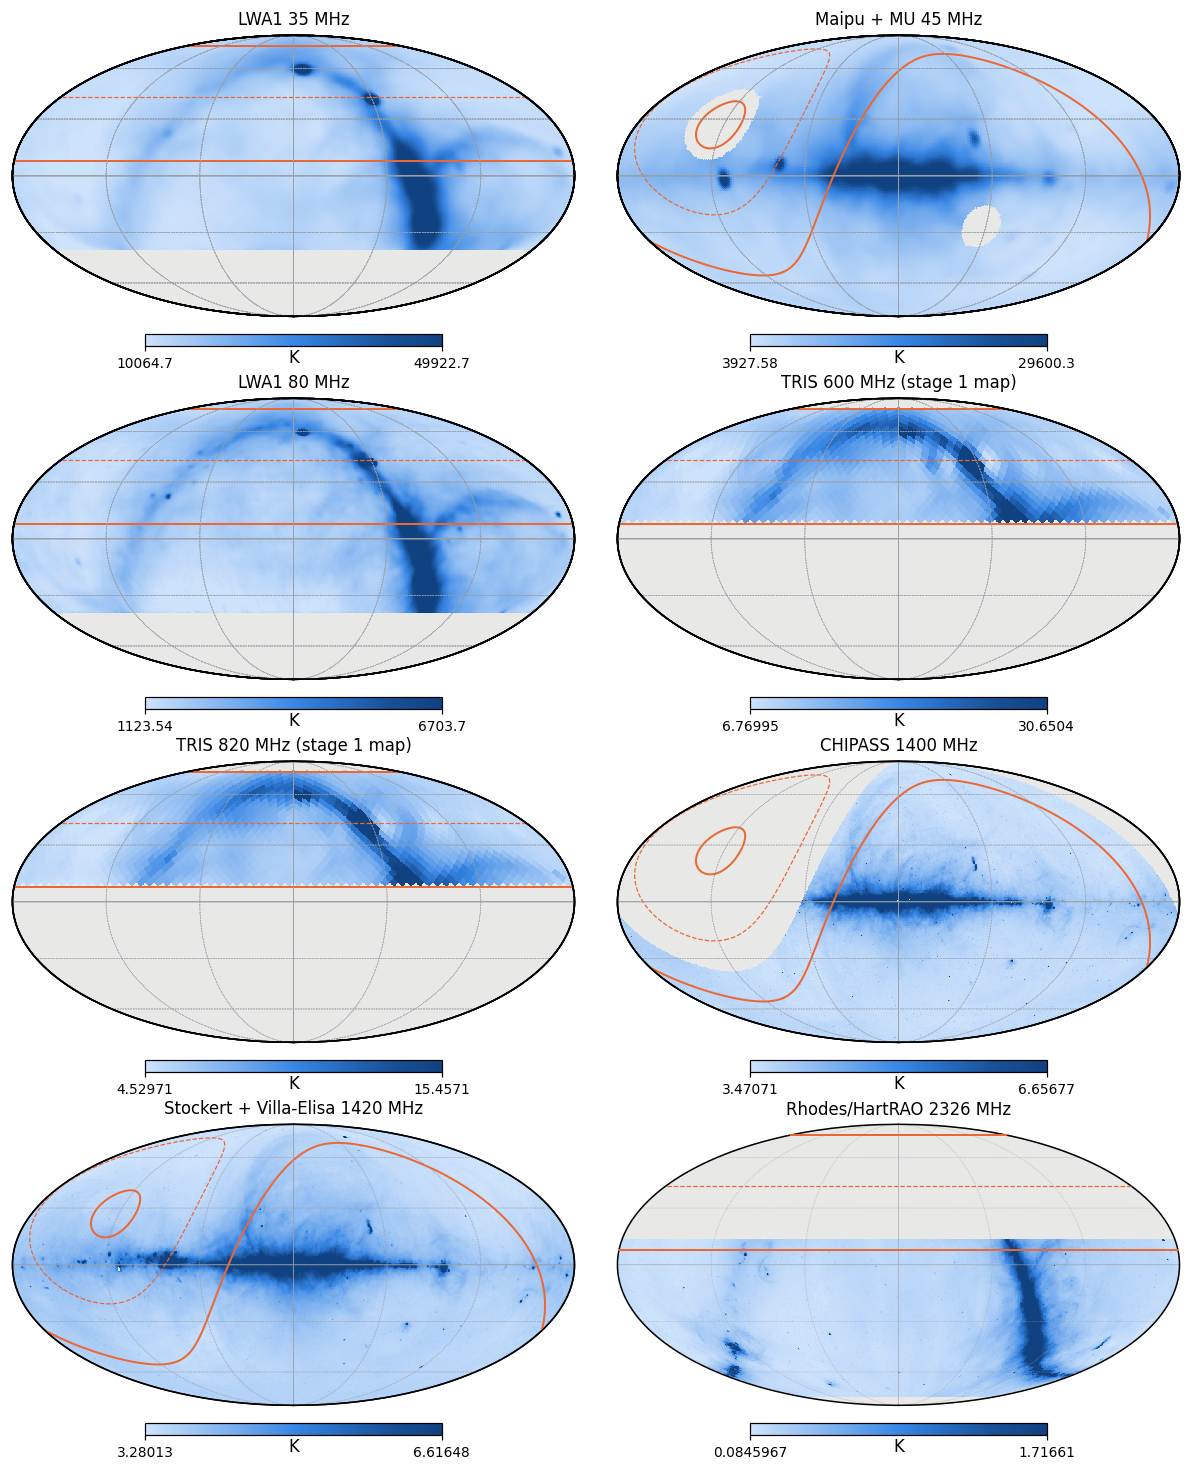

In [3]:
panels = [(m["name"], m["sky"], m["frame"]) for m in inp.fit_maps]
for f, name in zip((600, 820), TRIS_NAMES):
    panels.append((name, inp.stage1.band_map("sky_k", f), "C"))
panels.sort(key=lambda p: FREQ[p[0]])
rows = int(np.ceil(len(panels) / 2))
fig = plt.figure(figsize=(11, 3.3 * rows))
for k, (name, m, frame) in enumerate(panels):
    lo, hi = lims(m)
    hp.mollview(m, coord=frame, sub=(rows, 2, k + 1), fig=fig.number, cmap=SEQ, min=lo, max=hi,
                unit="K", title=f"{name}", **MKW)
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
    stripe_lines(frame)
save(fig, "fig01_maps_used")
plt.show()

---
## Figure 2 — The target and the TRIS stripe

Left: the destriped-only Haslam map at full resolution, drawn in equatorial (log scale),
with the stripe outlined. Right: the same map matched to the TRIS beam at nside 16, inside
the stripe only. This is the "old Haslam" the corrections are measured against.

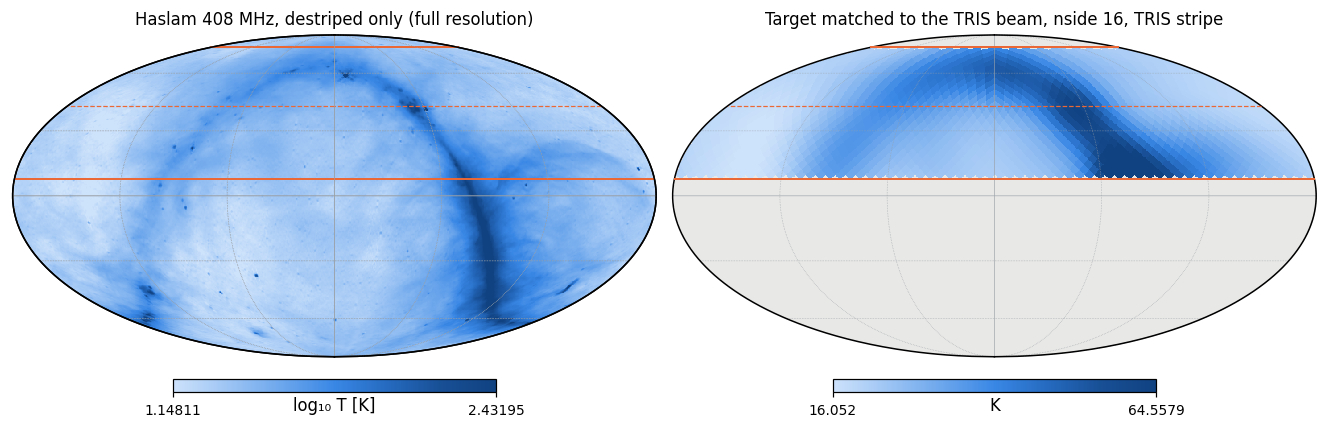

In [4]:
fig = plt.figure(figsize=(12, 3.9))
target = inp.target["sky"]
hp.mollview(np.log10(target), coord=["G", "C"], sub=(1, 2, 1), fig=fig.number, cmap=SEQ,
            min=np.log10(np.nanpercentile(target, 1)), max=np.log10(np.nanpercentile(target, 99.5)),
            unit="log₁₀ T [K]", title=f"{inp.target['name']} (full resolution)", **MKW)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
stripe_lines("C")
old = np.where(BAND, MR["old"], np.nan)
lo, hi = lims(old)
hp.mollview(old, coord="C", sub=(1, 2, 2), fig=fig.number, cmap=SEQ, min=lo, max=hi, unit="K",
            title="Target matched to the TRIS beam, nside 16, TRIS stripe", **MKW)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
stripe_lines("C")
save(fig, "fig02_target_stripe")
plt.show()

---
## Figure 3 — Slices along the TRIS stripe

Every map used in the fit, cut to the stripe's declinations (RA increasing to the left),
each sampled pixel by pixel at its own RA/Dec at native resolution. Grey: not observed.

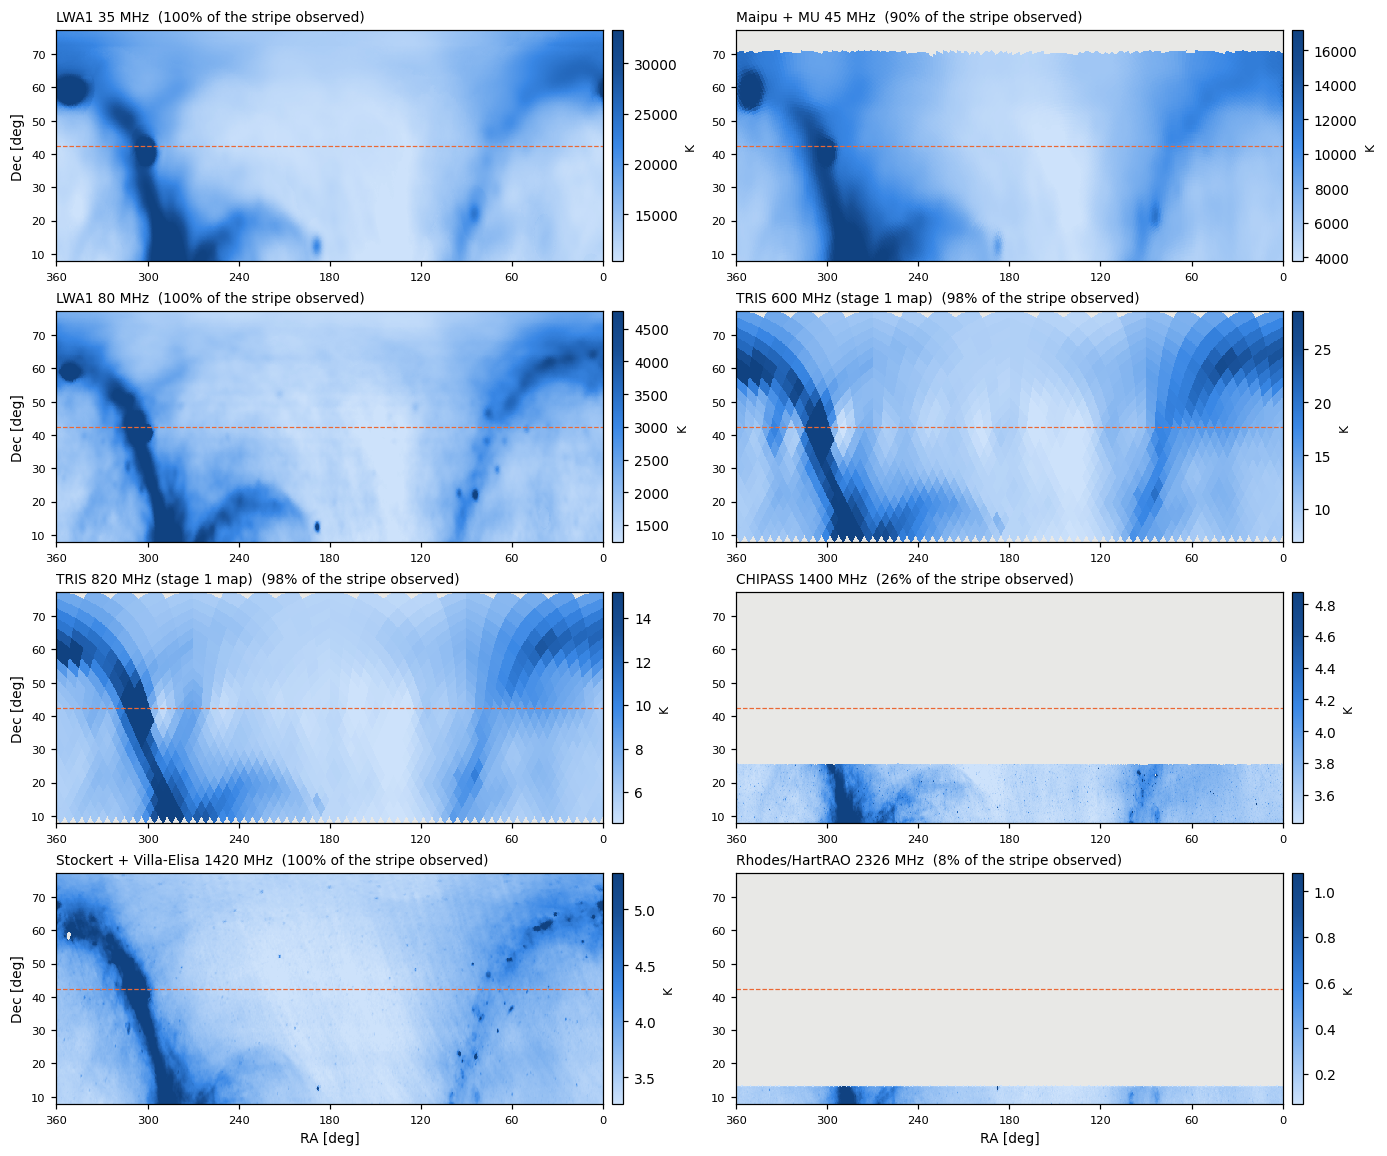

In [5]:
SL_RA = np.linspace(360, 0, 1441)
SL_DEC = np.linspace(STRIPE_DEC[0], STRIPE_DEC[1], 281)

def slice_image(m, frame):
    ra2, dec2 = np.meshgrid(SL_RA, SL_DEC)
    th, ph = np.radians(90 - dec2).ravel(), np.radians(ra2).ravel()
    if frame != "C":
        th, ph = hp.Rotator(coord=["C", frame])(th, ph)
    return m[hp.ang2pix(hp.get_nside(m), th, ph)].reshape(ra2.shape)

fig, axes = plt.subplots(rows, 2, figsize=(12.5, 2.6 * rows), squeeze=False, constrained_layout=True)
for ax, (name, m, frame) in zip(axes.flat, panels):
    img = slice_image(m, frame)
    seen = np.isfinite(img)
    lo, hi = (np.percentile(img[seen], [2, 98]) if seen.any() else (0, 1))
    im = ax.imshow(np.ma.masked_invalid(img), origin="lower", aspect="auto", cmap=SLICE,
                   vmin=lo, vmax=hi, interpolation="nearest",
                   extent=[360, 0, STRIPE_DEC[0], STRIPE_DEC[1]])
    ax.axhline(BORESIGHT, color="#eb6834", lw=0.8, ls="--")
    ax.set_title(f"{name}  ({100 * seen.mean():.0f}% of the stripe observed)", fontsize=9, loc="left")
    ax.set_xticks(np.arange(360, -1, -60)); ax.tick_params(labelsize=7.5)
    fig.colorbar(im, ax=ax, pad=0.01, fraction=0.04).set_label("K", fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("RA [deg]")
for ax in axes[:, 0]:
    ax.set_ylabel("Dec [deg]")
for ax in axes.flat[len(panels):]:
    ax.axis("off")
save(fig, "fig03_stripe_slices")
plt.show()

---
## Figure 4 — The TRIS maps regenerated from the rings, and their TODs

Top: stage 1's maps (limTOD's TOD → map Wiener filter). Below: the ring data, with error
bars that are the **published statistical uncertainties** from the archive, exactly as given.
The line is the model the map predicts for the same samples: the map seen through the TRIS
beam, plus the fitted zero level, $\sum_p B_{tp}\hat{x}_p + \hat{z}$. Underneath is the
residual, data − model (stage 1's `residual_k`).

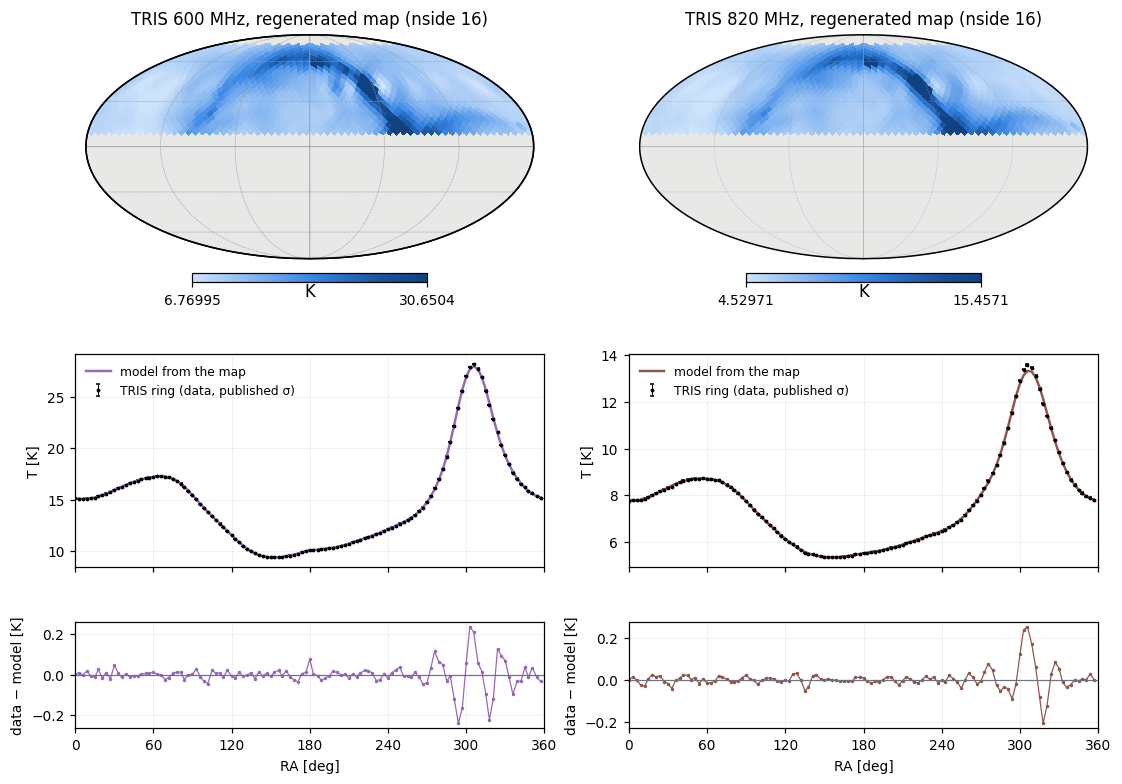

In [6]:
fig = plt.figure(figsize=(12, 8.2))
gs = fig.add_gridspec(3, 2, height_ratios=[1.25, 1, 0.5], hspace=0.28, wspace=0.18)
for col, f in enumerate((600, 820)):
    i = inp.stage1.index(f)
    ring = inp.rings[f]
    m = inp.stage1.band_map("sky_k", f)
    lo, hi = lims(m)
    plt.sca(fig.add_subplot(gs[0, col]))
    hp.mollview(m, coord="C", hold=True, cmap=SEQ, min=lo, max=hi, unit="K",
                title=f"TRIS {f} MHz, regenerated map (nside {NSIDE})", **MKW)
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
    data, resid = inp.stage1["data_k"][i], inp.stage1["residual_k"][i]
    ra = inp.stage1["ra_deg"][i]
    ax = fig.add_subplot(gs[1, col]); axr = fig.add_subplot(gs[2, col], sharex=ax)
    ax.errorbar(ra, data, yerr=np.asarray(ring.statistical_uncertainty_k), fmt=".", ms=3, color="k", elinewidth=0.7,
                capsize=1.5, label="TRIS ring (data, published σ)")
    ax.plot(ra, data - resid, "-", color=COLOUR[TRIS_NAMES[col]], lw=1.6, label="model from the map")
    ax.set_ylabel("T [K]"); ax.legend(fontsize=8, frameon=False)
    ax.tick_params(labelbottom=False)
    axr.plot(ra, resid, ".-", ms=2.5, lw=0.8, color=COLOUR[TRIS_NAMES[col]])
    axr.axhline(0, color="#6b7280", lw=0.8)
    axr.set_ylabel("data − model [K]"); axr.set_xlabel("RA [deg]")
    for a in (ax, axr):
        a.set_xlim(0, 360); a.set_xticks(np.arange(0, 361, 60)); a.grid(alpha=0.18, lw=0.6)
save(fig, "fig04_tris_maps_and_tods")
plt.show()

---
## Figure 5 — Pixel-by-pixel SED fits

Twelve stripe pixels across the range of sky brightness (ARCADE 2 is excluded,
`sed.exclude_maps`). Each panel shows the points with error bars (CMB removed, RJ), the best-fit power
law, and the target (open square: old Haslam, not fitted). Underneath is the residual,
(data − fit)/σ.

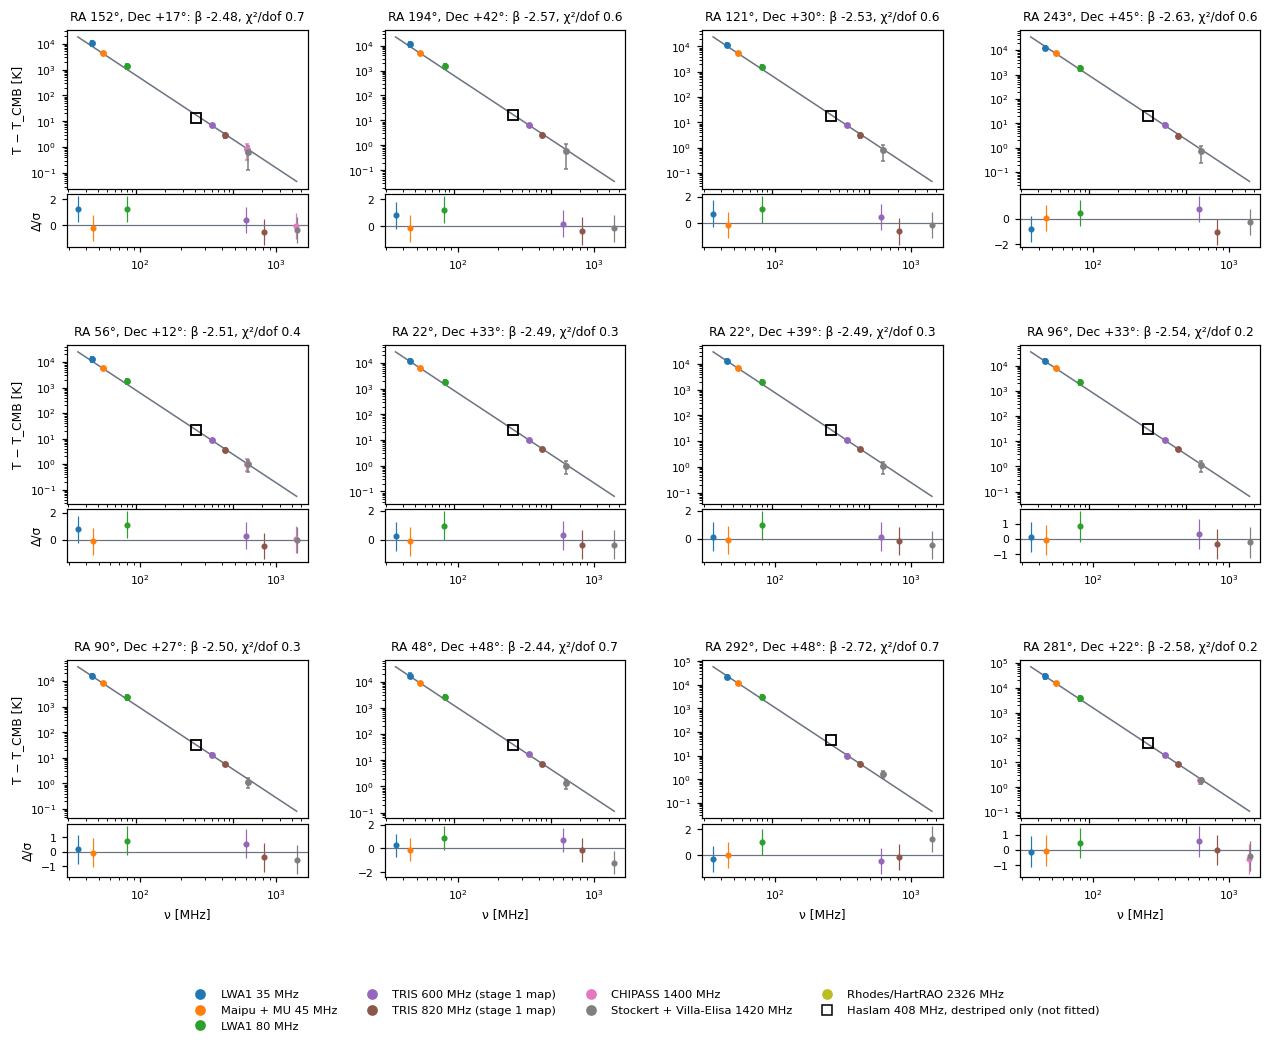

In [7]:
pts = MR["points"]
pix_all = np.array(sorted(pts))
old_vals = MR["old"][pix_all]
arc_any = any(any("ARCADE" in n for n in pts[p][3]) for p in pix_all)
qs = np.percentile(old_vals, np.linspace(3, 97, 8 if arc_any else 12))   # 12 panels either way
choice = [pix_all[np.argmin(np.abs(old_vals - q))] for q in qs]
arc = [p for p in pix_all if any("ARCADE" in n for n in pts[p][3])]
choice += [arc[k] for k in np.linspace(0, len(arc) - 1, 4).astype(int)] if arc else []
choice = list(dict.fromkeys(choice))[:12]

cmb408 = sky_maps.cmb_rj_k(sp.NU0_MHZ)
fig = plt.figure(figsize=(14, 10))
outer = fig.add_gridspec(3, 4, hspace=0.45, wspace=0.32)
grid_nu = np.geomspace(25, 4500, 200)
for k, p in enumerate(choice):
    nu, t, s, names, r = pts[p]
    inner = outer[k // 4, k % 4].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.05)
    ax, axr = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
    for n_, t_, s_, name in zip(nu, t, s, names):
        ax.errorbar(n_, t_, yerr=s_, fmt="o", ms=3.5, color=COLOUR[name], elinewidth=1, capsize=1.5)
        axr.errorbar(n_, (t_ - sp.power_law(n_, r["A"], r["beta"])) / s_, yerr=1, fmt="o", ms=3,
                     color=COLOUR[name], elinewidth=0.8)
    ax.plot(grid_nu, sp.power_law(grid_nu, r["A"], r["beta"]), "-", color="#6b7280", lw=1)
    ax.plot(408, MR["old"][p] - cmb408, "s", mfc="none", mec="k", ms=6, mew=1.2)
    ax.set_xscale("log"); ax.set_yscale("log"); axr.set_xscale("log")
    ra_p, dec_p = hp.pix2ang(NSIDE, p, lonlat=True)
    ax.set_title(f"RA {ra_p:.0f}°, Dec {dec_p:+.0f}°: β {r['beta']:.2f}, χ²/dof {r['chi2_dof']:.1f}",
                 fontsize=8)
    ax.tick_params(labelbottom=False, labelsize=7); axr.tick_params(labelsize=7)
    axr.axhline(0, color="#6b7280", lw=0.8)
    if k % 4 == 0:
        ax.set_ylabel("T − T_CMB [K]", fontsize=8); axr.set_ylabel("Δ/σ", fontsize=8)
    if k // 4 == 2:
        axr.set_xlabel("ν [MHz]", fontsize=8)
handles = [plt.Line2D([], [], marker="o", ls="", color=COLOUR[n], label=n) for n in ORDER if n != inp.target["name"]]
handles.append(plt.Line2D([], [], marker="s", ls="", mfc="none", mec="k", label=f"{inp.target['name']} (not fitted)"))
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=7.5, frameon=False, bbox_to_anchor=(0.5, -0.04))
save(fig, "fig05_sed_fits")
plt.show()

---
## Figure 5b — Sample-by-sample SED fits (TOD route)

The same fit along the TRIS ring. Twelve of the 120 samples, spread in RA (ARCADE 2 is
excluded, `sed.exclude_maps`). The points are the real TRIS ring data and
every map's TOD as limTOD observes it through the TRIS beam (CMB removed, RJ), with the
best-fit power law. The open square is old Haslam's TOD at that sample (not fitted).
Underneath is the residual, (data − fit)/σ.

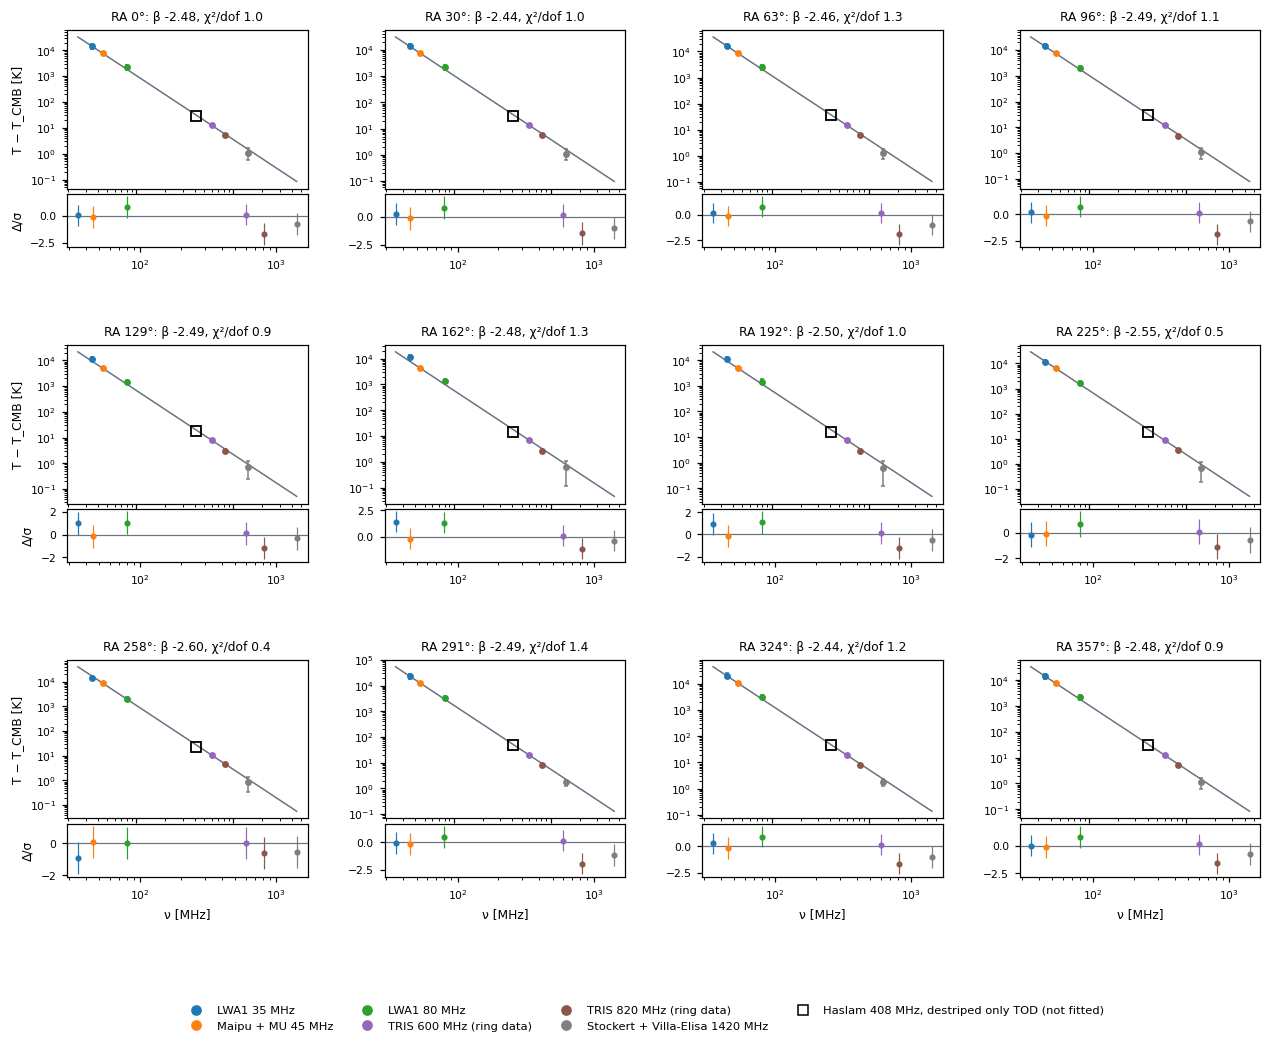

In [8]:
tpts = TR["points"]
def colour_of(name):
    # Ring data share the TRIS colours used for the stage 1 maps.
    if name.startswith("TRIS 600"):
        return COLOUR[TRIS_NAMES[0]]
    if name.startswith("TRIS 820"):
        return COLOUR[TRIS_NAMES[1]]
    return COLOUR[name]

samples = sorted(tpts)
with_arc = [k for k in samples if any("ARCADE" in n for n in tpts[k][3])]
without = [k for k in samples if k not in with_arc]
pick = [without[i] for i in np.linspace(0, len(without) - 1, 8 if with_arc else 12).astype(int)]
pick += [with_arc[i] for i in np.linspace(0, len(with_arc) - 1, 4).astype(int)] if with_arc else []
pick = sorted(dict.fromkeys(pick), key=lambda k: inp.ra[k])[:12]

fig = plt.figure(figsize=(14, 10))
outer = fig.add_gridspec(3, 4, hspace=0.45, wspace=0.32)
for k, t_idx in enumerate(pick):
    nu, t, s, names_t, r = tpts[t_idx]
    inner = outer[k // 4, k % 4].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.05)
    ax, axr = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
    for n_, t_, s_, name in zip(nu, t, s, names_t):
        c = colour_of(name)
        ax.errorbar(n_, t_, yerr=s_, fmt="o", ms=3.5, color=c, elinewidth=1, capsize=1.5)
        axr.errorbar(n_, (t_ - sp.power_law(n_, r["A"], r["beta"])) / s_, yerr=1, fmt="o", ms=3,
                     color=c, elinewidth=0.8)
    ax.plot(grid_nu, sp.power_law(grid_nu, r["A"], r["beta"]), "-", color="#6b7280", lw=1)
    ax.plot(408, TR["target_tod"][t_idx] - cmb408, "s", mfc="none", mec="k", ms=6, mew=1.2)
    ax.set_xscale("log"); ax.set_yscale("log"); axr.set_xscale("log")
    ax.set_title(f"RA {inp.ra[t_idx]:.0f}°: β {r['beta']:.2f}, χ²/dof {r['chi2_dof']:.1f}", fontsize=8)
    ax.tick_params(labelbottom=False, labelsize=7); axr.tick_params(labelsize=7)
    axr.axhline(0, color="#6b7280", lw=0.8)
    if k % 4 == 0:
        ax.set_ylabel("T − T_CMB [K]", fontsize=8); axr.set_ylabel("Δ/σ", fontsize=8)
    if k // 4 == 2:
        axr.set_xlabel("ν [MHz]", fontsize=8)
used = sorted({n for t_idx in pick for n in tpts[t_idx][3]}, key=lambda n: FREQ.get(n, 600.5 if "600" in n else 817.8))
handles = [plt.Line2D([], [], marker="o", ls="", color=colour_of(n), label=n) for n in used]
handles.append(plt.Line2D([], [], marker="s", ls="", mfc="none", mec="k", label=f"{inp.target['name']} TOD (not fitted)"))
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=7.5, frameon=False, bbox_to_anchor=(0.5, -0.04))
save(fig, "fig05b_sed_fits_tod")
plt.show()

---
## Figure 6 — Best fit − map, every map used

$T_\mathrm{best\,fit} - T_\mathrm{map}$, in kelvin, over the TRIS stripe, for every map that
entered the per-pixel fit (map route). Both are Rayleigh-Jeans temperatures with the CMB
removed, at that survey's own frequency. Positive (red) means the best-fit power law lies
above that survey's map at that pixel. A survey that sits consistently above or below the
common power law shows as one colour. The surveys span ~0.1 K to ~10⁴ K, so **each panel
has its own colour scale**, symmetric about zero. Each map's median is printed under the
figure.

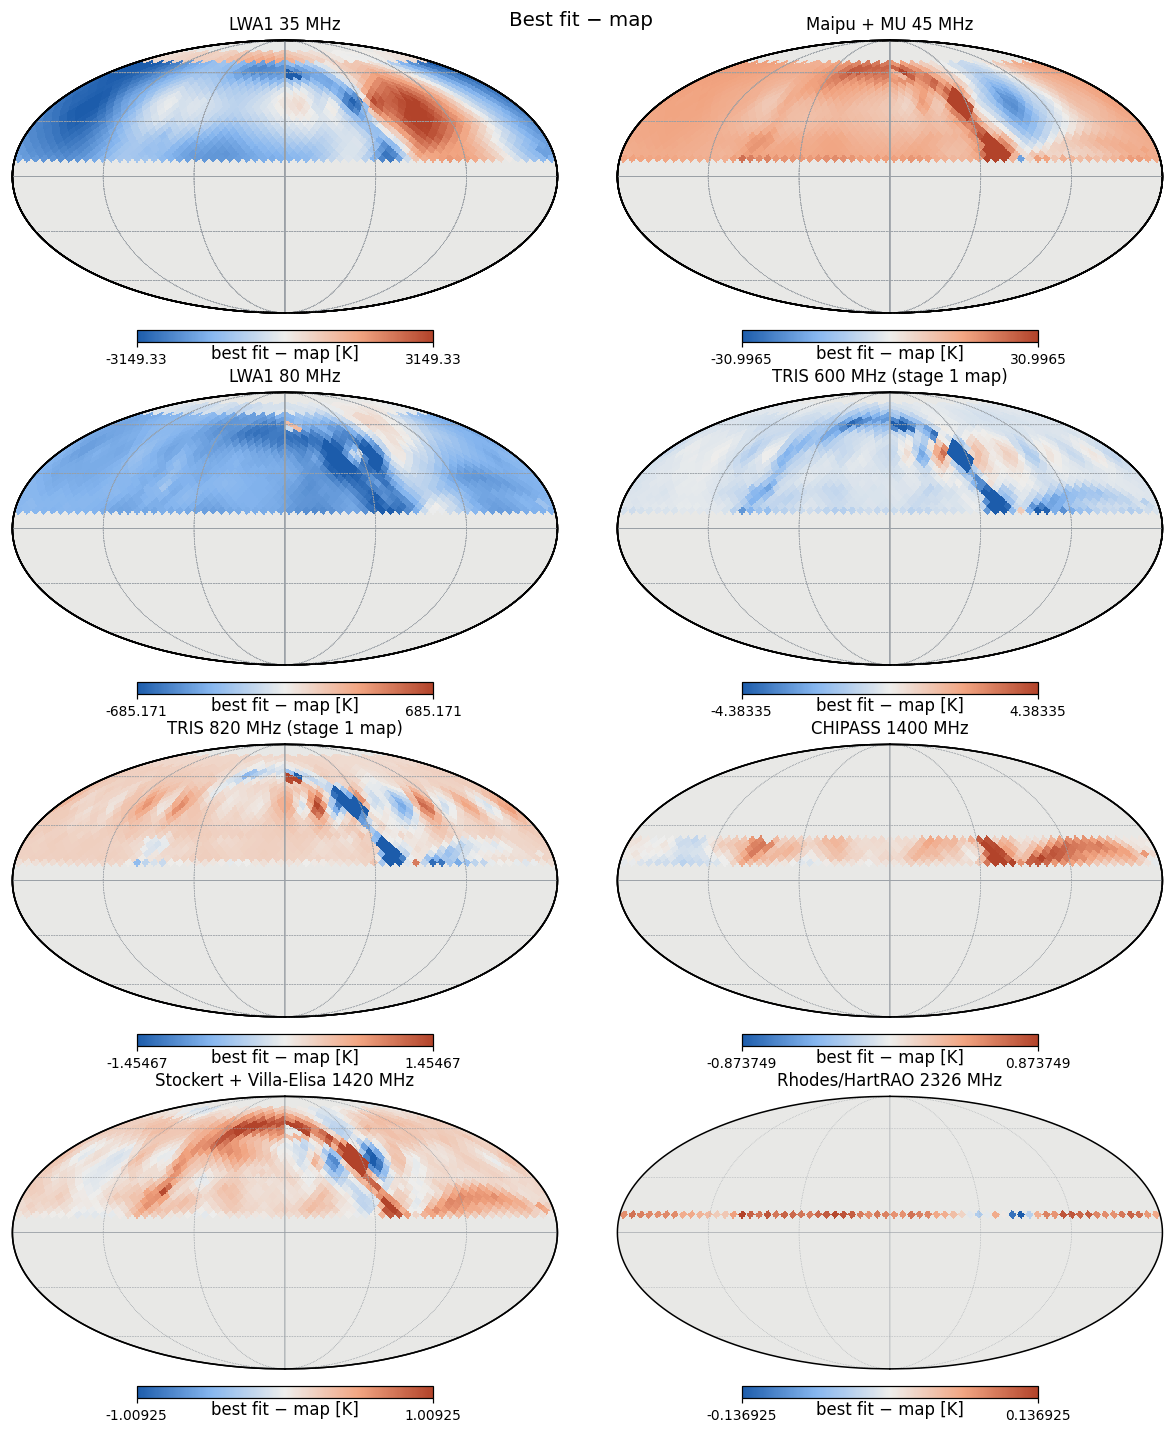

map                                   median best fit − map [K]                16–84% [K]  pixels
LWA1 35 MHz                                              -886.8           -2189 to +837.4    1272
Maipu + MU 45 MHz                                         +12.8           +5.839 to +15.6    1200
LWA1 80 MHz                                              -358.2          -458.9 to -201.1    1272
TRIS 600 MHz (stage 1 map)                               -0.464         -1.163 to -0.1947    1272
TRIS 820 MHz (stage 1 map)                              +0.2444      +0.004589 to +0.3469    1272
CHIPASS 1400 MHz                                        +0.1982       +0.01413 to +0.4944     382
Stockert + Villa-Elisa 1420 MHz                         +0.1682         +0.015 to +0.3968    1269
Rhodes/HartRAO 2326 MHz                                +0.08738       +0.04433 to +0.1136      64


In [9]:
names = [n for n in ORDER if n in MR["fit_minus_map"]]
rows6 = int(np.ceil(len(names) / 2))
fig = plt.figure(figsize=(11, 3.2 * rows6))
for k, name in enumerate(names):
    r = MR["fit_minus_map"][name]                 # K, RJ, CMB removed
    span = float(np.nanpercentile(np.abs(r), 98)) or 1.0
    hp.mollview(r, coord="C", sub=(rows6, 2, k + 1), fig=fig.number, cmap=DIV, min=-span, max=span,
                unit="best fit − map [K]", title=name, **MKW)
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
fig.suptitle("Best fit − map", fontsize=13, y=1.0)
save(fig, "fig06_fit_residual_maps")
plt.show()

print(f"{'map':<36}{'median best fit − map [K]':>27}{'16–84% [K]':>26}{'pixels':>8}")
for name in names:
    r = MR["fit_minus_map"][name]
    lo16, hi84 = np.nanpercentile(r, [16, 84])
    print(f"{name:<36}{np.nanmedian(r):+27.4g}{f'{lo16:+.4g} to {hi84:+.4g}':>26}{int(np.isfinite(r).sum()):8d}")

---
## Figure 6b — Best fit − data, TOD route

The TOD-route counterpart of Figure 6: at each of the 120 ring samples, the best-fit power
law minus each survey's value, in kelvin, against RA. TRIS 600 and 820 MHz are the real ring
data; the other surveys are their simulated TRIS TODs. A survey appears only at samples
where at least half of the TRIS beam falls on its observed sky. Each panel has its own
vertical scale. Medians are printed under the figure.

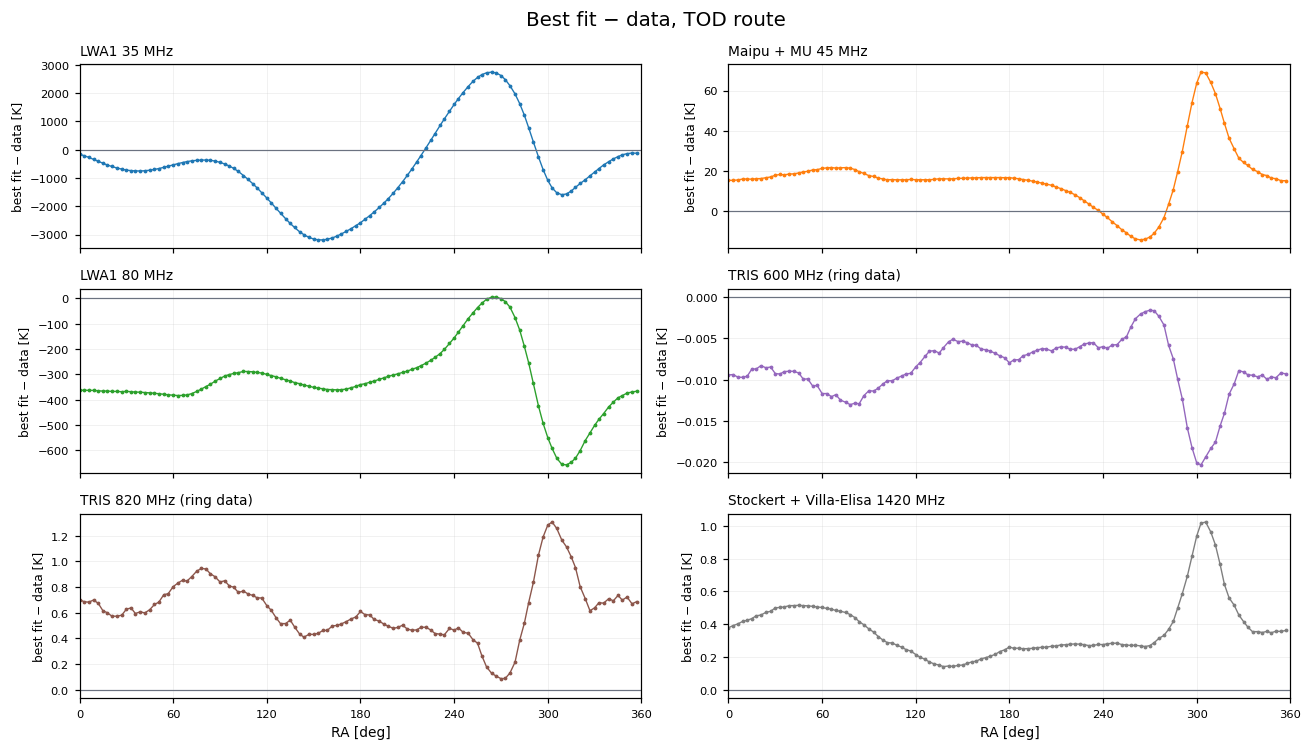

TOD                                   median best fit − data [K]                16–84% [K]  samples
LWA1 35 MHz                                               -664.5           -2243 to +766.6      120
Maipu + MU 45 MHz                                         +16.05            +6.62 to +21.3      120
LWA1 80 MHz                                               -347.2          -383.5 to -233.8      120
TRIS 600 MHz (ring data)                               -0.008705     -0.01168 to -0.005801      120
TRIS 820 MHz (ring data)                                 +0.6094         +0.441 to +0.8365      120
Stockert + Villa-Elisa 1420 MHz                          +0.3191        +0.2368 to +0.5051      120


In [10]:
resid_t = {}
for k, (nu, t, s, names_t, r) in TR["points"].items():
    for n_, t_, name in zip(nu, t, names_t):
        resid_t.setdefault(name, np.full(inp.ra.size, np.nan))[k] = sp.power_law(n_, r["A"], r["beta"]) - t_
order_t = sorted(resid_t, key=lambda n: FREQ.get(n, 600.5 if n.startswith("TRIS 600") else 817.8))
rows_t = int(np.ceil(len(order_t) / 2))
fig, axes = plt.subplots(rows_t, 2, figsize=(12, 2.3 * rows_t), sharex=True, squeeze=False)
for ax, name in zip(axes.flat, order_t):
    ax.plot(inp.ra, resid_t[name], ".-", ms=3, lw=0.9, color=colour_of(name))
    ax.axhline(0, color="#6b7280", lw=0.8)
    ax.set_title(name, fontsize=9, loc="left")
    ax.set_ylabel("best fit − data [K]", fontsize=8)
    ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 60)); ax.grid(alpha=0.18, lw=0.6)
    ax.tick_params(labelsize=7.5)
for ax in axes.flat[len(order_t):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("RA [deg]")
fig.suptitle("Best fit − data, TOD route", fontsize=13)
fig.tight_layout()
save(fig, "fig06b_tod_residuals")
plt.show()

print(f"{'TOD':<36}{'median best fit − data [K]':>28}{'16–84% [K]':>26}{'samples':>9}")
for name in order_t:
    r = resid_t[name]
    lo16, hi84 = np.nanpercentile(r, [16, 84])
    print(f"{name:<36}{np.nanmedian(r):+28.4g}{f'{lo16:+.4g} to {hi84:+.4g}':>26}{int(np.isfinite(r).sum()):9d}")

---
## Figure 7 — Best-fit Haslam from both routes, and the difference from old Haslam

Top: the best-fit 408 MHz Haslam over the TRIS stripe, from the map route (per-pixel fit)
and from the TOD route (old Haslam plus the ring correction mapped by the Wiener filter),
on one colour scale. Bottom: each minus old Haslam, on one shared symmetric scale.

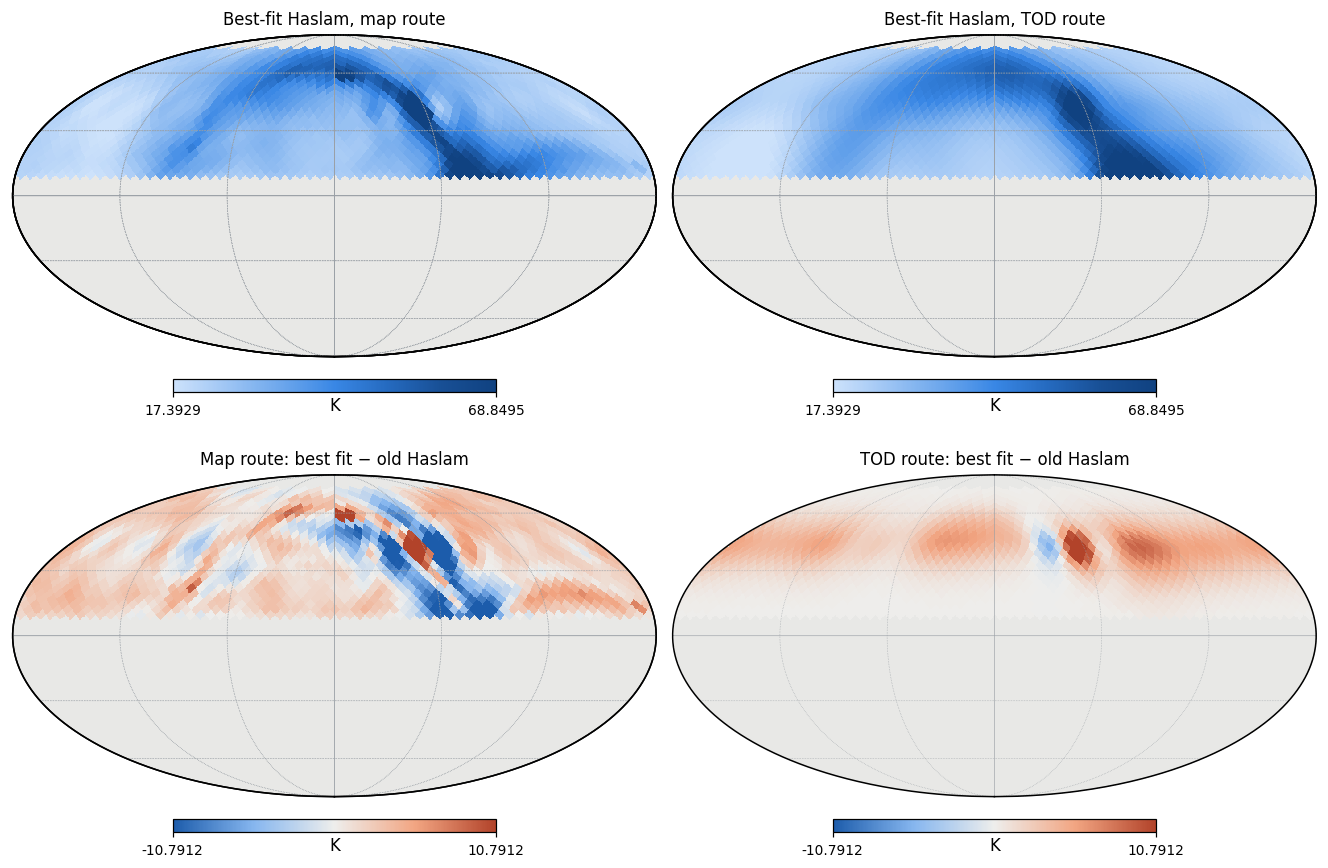

map route: best fit − old median +1.60 K (+6.1%) over 1272 pixels
TOD route: best fit − old median +1.02 K (+3.4%) over 1272 pixels


In [11]:
inb = BAND & np.isfinite(MR["pred"])
best_map = np.where(inb, MR["pred"], np.nan)
best_tod = np.where(BAND, TR["pred_map"], np.nan)
d_map = best_map - MR["old"]
d_tod = np.where(BAND, TR["delta"], np.nan)
lo, hi = np.nanpercentile(np.concatenate([best_map, best_tod]), [2, 98])
span_d = float(np.nanpercentile(np.abs(np.concatenate([d_map, d_tod])), 98))
fig = plt.figure(figsize=(12, 8.0))
for k, (title, m, cmap, a, b) in enumerate([
        ("Best-fit Haslam, map route", best_map, SEQ, lo, hi),
        ("Best-fit Haslam, TOD route", best_tod, SEQ, lo, hi),
        ("Map route: best fit − old Haslam", d_map, DIV, -span_d, span_d),
        ("TOD route: best fit − old Haslam", d_tod, DIV, -span_d, span_d)]):
    hp.mollview(m, coord="C", sub=(2, 2, k + 1), fig=fig.number, cmap=cmap, min=a, max=b, unit="K",
                title=title, **MKW)
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
save(fig, "fig07_bestfit_haslam_both_routes")
plt.show()
print(f"map route: best fit − old median {np.nanmedian(d_map):+.2f} K "
      f"({100 * np.nanmedian(d_map / MR['old']):+.1f}%) over {int(inb.sum())} pixels")
print(f"TOD route: best fit − old median {np.nanmedian(d_tod):+.2f} K "
      f"({100 * np.nanmedian(d_tod / MR['old']):+.1f}%) over {int(np.isfinite(d_tod).sum())} pixels")

---
## Figure 7b — The TOD route along the ring

Old Haslam's simulated TRIS TOD and the best-fit 408 MHz prediction (±1σ band) at each of
the 120 ring samples, with their difference below.

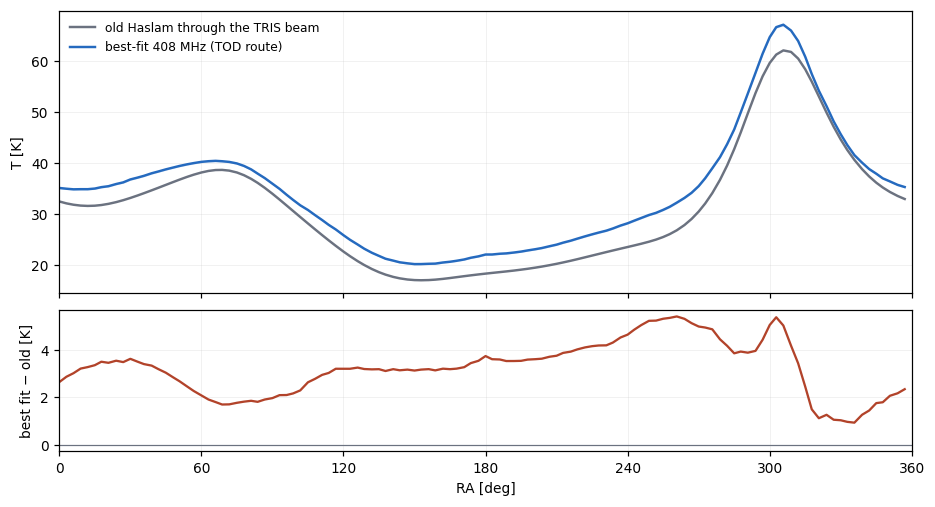

along the ring: best fit − old median +3.22 K (+10.9%)


In [12]:
fig, (ax, axd) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.08))
ax.plot(inp.ra, TR["target_tod"], "-", color="#6b7280", lw=1.6, label="old Haslam through the TRIS beam")
ax.plot(inp.ra, TR["pred"], "-", color="#256abf", lw=1.6, label="best-fit 408 MHz (TOD route)")
ax.fill_between(inp.ra, TR["pred"] - TR["sigma_pred"], TR["pred"] + TR["sigma_pred"], color="#256abf", alpha=0.2, lw=0)
ax.set_ylabel("T [K]"); ax.legend(fontsize=8, frameon=False); ax.grid(alpha=0.18, lw=0.6)
axd.plot(inp.ra, TR["delta_tod"], "-", color="#b2432a", lw=1.5)
axd.axhline(0, color="#6b7280", lw=0.8)
axd.set_ylabel("best fit − old [K]"); axd.set_xlabel("RA [deg]"); axd.grid(alpha=0.18, lw=0.6)
axd.set_xlim(0, 360); axd.set_xticks(np.arange(0, 361, 60))
save(fig, "fig07b_tod_route_ring")
plt.show()
print(f"along the ring: best fit − old median {np.nanmedian(TR['delta_tod']):+.2f} K "
      f"({100 * np.nanmedian(TR['delta_tod'] / TR['target_tod']):+.1f}%)")

---
## Figure 7c — (Best fit − old)/old, both routes

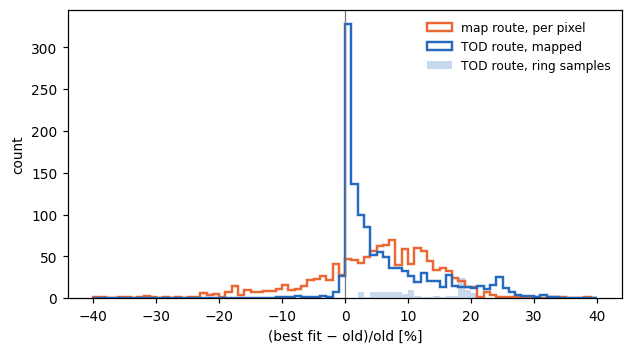

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
bins = np.linspace(-40, 40, 81)
ax.hist(100 * d_map[inb] / MR["old"][inb], bins=bins, histtype="step", lw=1.6, color="#eb6834",
        label="map route, per pixel")
ax.hist(100 * d_tod[BAND] / MR["old"][BAND], bins=bins, histtype="step", lw=1.6, color="#256abf",
        label="TOD route, mapped")
ax.hist(100 * TR["delta_tod"] / TR["target_tod"], bins=bins, histtype="stepfilled", alpha=0.25,
        color="#256abf", label="TOD route, ring samples")
ax.axvline(0, color="#6b7280", lw=0.8)
ax.set_xlabel("(best fit − old)/old [%]"); ax.set_ylabel("count"); ax.legend(fontsize=8, frameon=False)
save(fig, "fig07c_fractional_difference_hist")
plt.show()

---
## Figure 7d — Every map through the TRIS beam, scaled to 408 MHz by a power law fitted without TRIS

Each survey's TOD (limTOD, the measured TRIS beam along the real ring, CMB removed) is
brought to 408 MHz with a power law fitted **without TRIS**:

1. At each of the 120 ring samples, fit $T(\nu) = A(\nu/408\,\mathrm{MHz})^\beta$ to every
   survey with data there except TRIS and Haslam (the target): LWA1 35 and 80 MHz,
   Maipu 45 MHz and Stockert 1420 MHz (ARCADE 2 is excluded, `sed.exclude_maps`). Error bars are the
   pipeline's own (`sed_prototype.sigma_for`).
2. Scale every survey, and the TRIS ring data, to 408 MHz with that sample's fitted β:
   $T_{408} = T(\nu)\,(408/\nu)^{\beta}$.

The surveys used in the fit then scatter around $A$ by their residuals. TRIS, which did not
enter the fit, can be compared with it directly, and so can Haslam.

**Sky models**, generated at 408 MHz without the CMB (`pygdsm`) and observed through the
same beam: GSM2008 (de Oliveira-Costa et al. 2008), GSM2016 (Zheng et al. 2017), and the
LWA1 low-frequency sky model, LFSM (Dowell et al. 2017). They need no scaling at 408 MHz.
GSM2008 and GSM2016 are built partly from Haslam; LFSM is built from LWA1 and other
low-frequency surveys, and 408 MHz is the top of its range.

**Top:** $T_{408}$ against LST (= RA on the TRIS ring). **Bottom:** each divided by the
fitted $A$, so 1 means "agrees with the non-TRIS power law".

**Haslam survey zones** (Haslam et al. 1982), in the strip above the top panel, with their RA
edges as vertical lines through both panels. RA extents (increasing RA, wrapping through 0°)
and Dec extents:

| zone | RA | Dec |
|---|---|---|
| Parkes | full circle | −89.8° to −8.4° |
| Effelsberg | 179.5° → 59.9° | −8.9° to +24.4° |
| Jodrell MkI | 359.5° → 160.1° | −20.7° to +44.8° |
| Jodrell MkIA | full circle | −20.7° to +89.8° |

Only zones whose Dec range comes within one beam FWHM (23.4°) of the ring (Dec +42.4°)
are drawn, so Parkes is left out. Jodrell MkIA and MkI contain the ring centre. Effelsberg
reaches only the beam's southern wing (+24.4° is 18° below the ring, where the beam response is ~0.2).
Dashed lines: Jodrell MkI edges; dotted lines: Effelsberg edges.

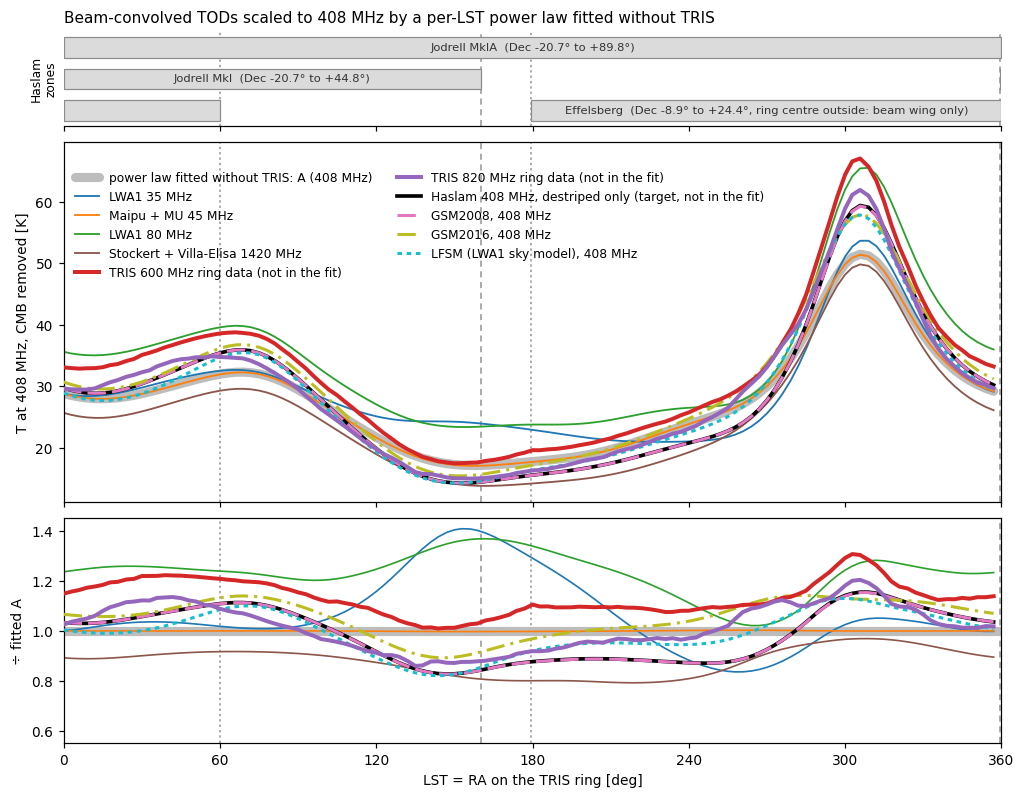

non-TRIS power law: 120/120 samples fitted, 4–4 points each, median β -2.528 (range -2.634 to -2.489)
series                                        median ÷ A     min     max
TRIS 600 MHz ring data                             1.124   1.009   1.306
TRIS 820 MHz ring data                             1.017   0.859   1.203
Haslam 408 MHz, destriped only                     1.009   0.827   1.154
GSM2008                                            1.008   0.826   1.152
GSM2016                                            1.066   0.892   1.141
LFSM (LWA1 sky model)                              0.994   0.820   1.129
LWA1 35 MHz                                        1.028   0.835   1.408
Maipu + MU 45 MHz                                  0.999   0.996   1.002
LWA1 80 MHz                                        1.241   1.020   1.367
Stockert + Villa-Elisa 1420 MHz                    0.892   0.792   0.968


In [14]:
from pygdsm import GlobalSkyModel, GlobalSkyModel16, LowFrequencySkyModel

NU_REF = sp.NU0_MHZ                                      # 408 MHz
n_s = inp.ra.size

# 1. Per-sample power law from every survey except TRIS (and the Haslam target).
BETA_NT, A_NT, N_NT = (np.full(n_s, np.nan) for _ in range(3))
for k in range(n_s):
    nus, ts, ss = [], [], []
    for m in inp.fit_maps:
        d = inp.tods[m["name"]]
        if d["good"][k]:
            t = float(sky_maps.rj_excess(d["tod"][k], m))
            nus.append(m["freq_mhz"]); ts.append(t); ss.append(float(sp.sigma_for(m, t)))
    r = sp.fit_power_law(nus, ts, ss)
    if r:
        BETA_NT[k], A_NT[k], N_NT[k] = r["beta"], r["A"], r["n"]

def to_408(t_excess, nu):
    return np.asarray(t_excess, dtype=float) * (NU_REF / nu) ** BETA_NT

# 2. Everything at 408 MHz, CMB removed.
SCALED = {}
for m in inp.fit_maps:
    d = inp.tods[m["name"]]
    if d["good"].any():
        SCALED[m["name"]] = np.where(d["good"], to_408(sky_maps.rj_excess(d["tod"], m), m["freq_mhz"]), np.nan)
HASLAM_408 = np.asarray(sky_maps.rj_excess(inp.tods[inp.target["name"]]["tod"], inp.target), dtype=float)
TRIS_408 = {}
for f, name in zip((600, 820), TRIS_NAMES):
    ring = inp.rings[f]
    nu = ring.effective_frequency_mhz
    TRIS_408[f] = to_408(np.asarray(ring.temperature_k) - sky_maps.cmb_rj_k(nu), nu)

# 3. The sky models at 408 MHz (no CMB), observed through the same beam on the same ring.
def model_tod(sky_gal):
    m = sky_gal if hp.get_nside(sky_gal) <= 64 else hp.ud_grade(sky_gal, 64)
    m = hp.Rotator(coord=["G", "C"]).rotate_map_pixel(m)
    return np.asarray(inp.observe(hp.ud_grade(m, inp.nside)), dtype=float)

MODELS = {
    "GSM2008": GlobalSkyModel(include_cmb=False).generate(NU_REF),
    "GSM2016": GlobalSkyModel16(data_unit="TRJ", resolution="lo", include_cmb=False).generate(NU_REF),
    "LFSM (LWA1 sky model)": LowFrequencySkyModel(include_cmb=False).generate(NU_REF),
}
MODEL_408 = {name: model_tod(np.asarray(sky, dtype=float)) for name, sky in MODELS.items()}
# This figure's own palette: tab10 without its grey (the fitted-A band is grey, Haslam black).
TAB10 = [col for i, col in enumerate(plt.get_cmap("tab10").colors) if i != 7]
C7D = dict(zip([n for n in ORDER if n in SCALED or n in TRIS_NAMES] + list(MODEL_408), TAB10))
MODEL_STYLE = {"GSM2008": (C7D["GSM2008"], (0, (6, 2))), "GSM2016": (C7D["GSM2016"], (0, (6, 2, 1, 2))),
               "LFSM (LWA1 sky model)": (C7D["LFSM (LWA1 sky model)"], (0, (1.5, 1.5)))}

fig, (axz, ax, axr) = plt.subplots(3, 1, figsize=(11, 8.4), sharex=True,
                                   gridspec_kw=dict(height_ratios=[0.42, 1.6, 1], hspace=0.07))
ax.plot(inp.ra, A_NT, "-", color="#bdbdbd", lw=6, solid_capstyle="round",
        label="power law fitted without TRIS: A (408 MHz)", zorder=1)
# Lines only: thin solid for the surveys in the fit, thick for TRIS and Haslam, patterned
# lines for the sky models.
for name, v in SCALED.items():
    ax.plot(inp.ra, v, "-", color=C7D[name], lw=1.2, label=name, zorder=2)
    axr.plot(inp.ra, v / A_NT, "-", color=C7D[name], lw=1.1, zorder=2)
for f, name in zip((600, 820), TRIS_NAMES):
    ax.plot(inp.ra, TRIS_408[f], "-", color=C7D[name], lw=2.6,
            label=f"TRIS {f} MHz ring data (not in the fit)", zorder=4)
    axr.plot(inp.ra, TRIS_408[f] / A_NT, "-", color=C7D[name], lw=2.6, zorder=4)
ax.plot(inp.ra, HASLAM_408, "-", color="k", lw=2.4, label=f"{inp.target['name']} (target, not in the fit)", zorder=3)
axr.plot(inp.ra, HASLAM_408 / A_NT, "-", color="k", lw=2.4, zorder=3)
for name, v in MODEL_408.items():
    c, ls = MODEL_STYLE[name]
    ax.plot(inp.ra, v, color=c, ls=ls, lw=2, label=f"{name}, 408 MHz", zorder=3)
    axr.plot(inp.ra, v / A_NT, color=c, ls=ls, lw=2, zorder=3)
axr.axhline(1, color="#bdbdbd", lw=6, zorder=1)
# Haslam 408 MHz survey zones (Haslam et al. 1982): RA runs from start to end in increasing RA,
# wrapping through 0 (None = full circle). A zone is marked if its Dec range comes within one
# beam FWHM of the ring (beam response >= 1/16); Parkes (Dec <= -8.4 deg) does not.
HASLAM_ZONES = [  # name, RA start, RA end, Dec min, Dec max, edge line style
    ("Jodrell MkIA", None, None, -20.7, +89.8, None),
    ("Jodrell MkI", 359.5, 160.1, -20.7, +44.8, (0, (4, 3))),
    ("Effelsberg", 179.5, 59.9, -8.9, +24.4, (0, (1.5, 2))),
    ("Parkes", None, None, -89.8, -8.4, None),
]
FWHM = inp.target_fwhm
ZONES = [z for z in HASLAM_ZONES if z[3] <= BORESIGHT + FWHM and z[4] >= BORESIGHT - FWHM]

def ra_segments(start, end):
    if start is None:
        return [(0, 360)]
    return [(start, end)] if start < end else [(start, 360), (0, end)]

for row, (name, start, end, d_lo, d_hi, ls) in enumerate(ZONES):
    segs = ra_segments(start, end)
    axz.broken_barh([(a, b - a) for a, b in segs], (row - 0.32, 0.64), color="0.86", edgecolor="0.55", lw=0.8)
    a, b = max(segs, key=lambda sg: sg[1] - sg[0])
    note = "" if d_lo <= BORESIGHT <= d_hi else ", ring centre outside: beam wing only"
    axz.text((a + b) / 2, row, f"{name}  (Dec {d_lo:+.1f}° to {d_hi:+.1f}°{note})",
             ha="center", va="center", fontsize=7.5, color="0.2")
    if start is not None:
        for edge in (start, end):
            for a_ in (axz, ax, axr):
                a_.axvline(edge, color="0.4", lw=1.0, ls=ls, alpha=0.7, zorder=0)
axz.set_ylim(len(ZONES) - 0.5, -0.5); axz.set_yticks([])
for side in ("left", "right", "top"):
    axz.spines[side].set_visible(False)
axz.set_ylabel("Haslam\nzones", fontsize=8)
ax.set_ylabel("T at 408 MHz, CMB removed [K]")
axr.set_ylabel("÷ fitted A"); axr.set_xlabel("LST = RA on the TRIS ring [deg]")
axr.set_xlim(0, 360); axr.set_xticks(np.arange(0, 361, 60))
lo_r, hi_r = np.nanpercentile(np.concatenate([HASLAM_408 / A_NT, TRIS_408[600] / A_NT, TRIS_408[820] / A_NT]
                                             + [v / A_NT for v in MODEL_408.values()]), [0.5, 99.5])
axr.set_ylim(min(0.55, lo_r - 0.05), max(1.45, hi_r + 0.05))
ax.legend(fontsize=8, frameon=False, ncol=2, loc="upper left", bbox_to_anchor=(0, 0.95))
axz.set_title("Beam-convolved TODs scaled to 408 MHz by a per-LST power law fitted without TRIS",
              loc="left", fontsize=10)
save(fig, "fig07d_scaled_tods_vs_lst")
plt.show()

print(f"non-TRIS power law: {int(np.isfinite(BETA_NT).sum())}/{n_s} samples fitted, {int(np.nanmin(N_NT))}–{int(np.nanmax(N_NT))} points each, "
      f"median β {np.nanmedian(BETA_NT):+.3f} (range {np.nanmin(BETA_NT):+.3f} to {np.nanmax(BETA_NT):+.3f})")
print(f"{'series':<44}{'median ÷ A':>12}{'min':>8}{'max':>8}")
rows = [(f"TRIS {f} MHz ring data", TRIS_408[f] / A_NT) for f in (600, 820)]
rows += [(f"{inp.target['name']}", HASLAM_408 / A_NT)] + [(n, v / A_NT) for n, v in MODEL_408.items()]
rows += [(n, v / A_NT) for n, v in SCALED.items()]
for name, ratio in rows:
    print(f"{name:<44}{np.nanmedian(ratio):12.3f}{np.nanmin(ratio):8.3f}{np.nanmax(ratio):8.3f}")

**Reading Figure 7d (run 2026-10-15, ARCADE 2 excluded).** The non-TRIS power law is fitted at
all 120 samples from 4 points each (LWA1 35 and 80, Maipu 45, Stockert 1420 MHz), median
β −2.58 (−2.65 to −2.51). Medians of each series ÷ the fitted 408 MHz amplitude A:

| series | median ÷ A | range |
|---|---|---|
| **TRIS 600 MHz** (not in the fit) | **1.23** | 1.10–1.29 |
| **TRIS 820 MHz** (not in the fit) | **1.12** | 0.95–1.20 |
| Haslam 408 MHz, destriped (target) | 1.04 | 0.87–1.14 |
| GSM2008 | 1.04 | 0.87–1.14 |
| GSM2016 | 1.11 | 0.94–1.21 |
| LFSM (LWA1 sky model) | 1.06 | 0.86–1.13 |
| LWA1 35 / Maipu 45 / LWA1 80 / Stockert 1420 MHz (in the fit) | 0.96 / 0.94 / 1.20 / 0.98 | — |

* **TRIS sits above the non-TRIS power law at almost every LST**: by 23% at 600 MHz and 12%
  at 820 MHz, in median. A power law through the other surveys does not reach the
  absolutely calibrated TRIS level. This is the same tension the TOD-route SED fit shows
  (Haslam ~13% low against a fit that includes TRIS).
* **Haslam, GSM2008, GSM2016 and LFSM all sit together, 4–11% above A.** GSM2008 follows
  Haslam almost exactly; it is built from Haslam. All four are well below TRIS 600.
* **The surveys in the fit scatter around A** by their residuals: LWA1 80 MHz sits ~20%
  high and Maipu ~6% low, which is the curvature a single power law cannot follow.
* **No more steps at LST 255–280° and 320–345°.** With ARCADE 2 in the fit, its two very
  precise points pulled A there and the ratios jumped (up to ×1.4–1.6); without it the
  ratios vary smoothly, and their maxima fall to 1.1–1.3.

---
## Figures 7e–7g — Figure 7d, grouped

The same series as Figure 7d (each ÷ the fitted 408 MHz amplitude A, so 1 = "agrees with the
non-TRIS power law"), split into panels by one property at a time. Colours are Figure 7d's.
Haslam (black) is repeated in every panel as the reference, and the Haslam zone strip and
edges are as in 7d.

* **7e — frequency relative to Haslam:** below 408 MHz (LWA1 35 and 80, Maipu 45), at 408 MHz
  (the sky models), above 408 MHz (TRIS 600 and 820, Stockert 1420). The below/above surveys
  are extrapolated to 408 MHz in opposite directions with the same β.
* **7f — native angular resolution** (FWHM before the TRIS beam): the TRIS beam itself
  (23.4°), 2–5° (LWA1, Maipu), ≤ 1° (Stockert 0.59°, Haslam 0.93°). Everything is observed
  through the TRIS beam, so this asks whether the beam matching depends on the starting
  resolution. The sky models are left out: their effective resolution is not a single number.
* **7g — individual data vs sky models:** the surveys and TRIS ring data in one panel, the
  three sky models in the other.


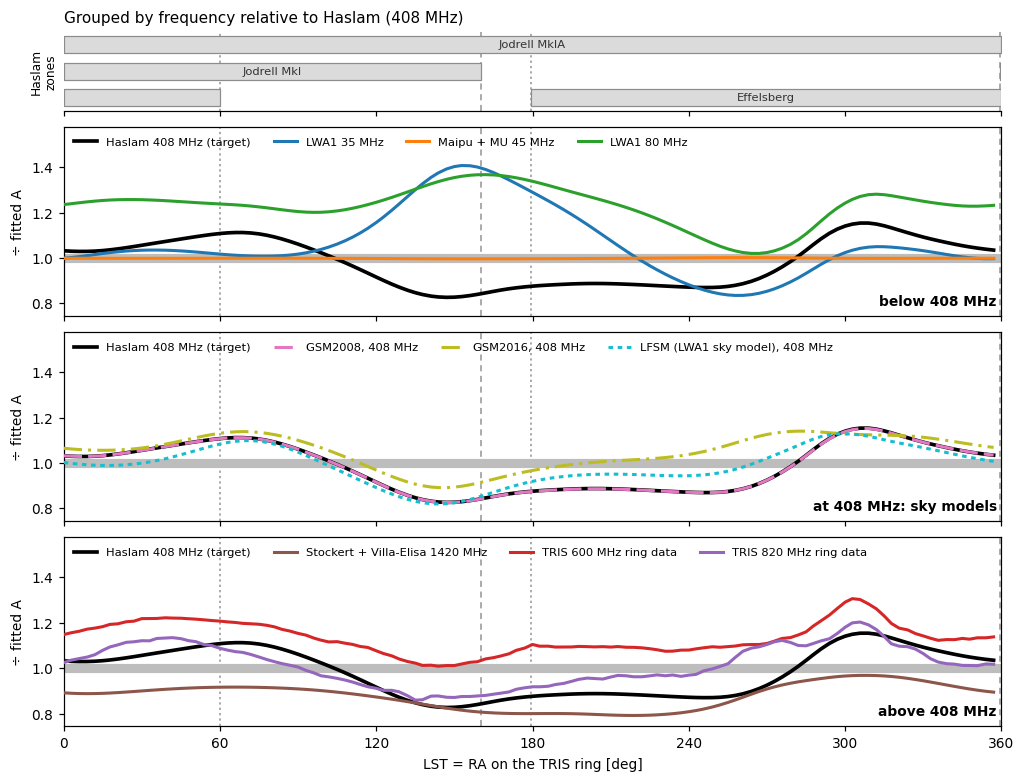

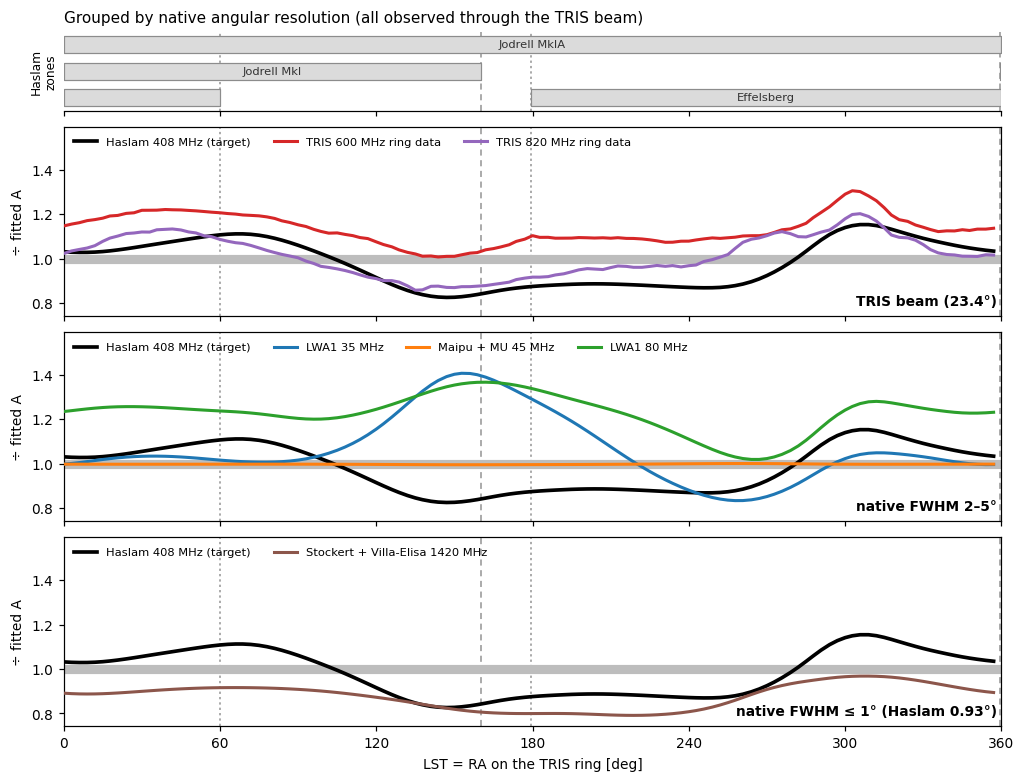

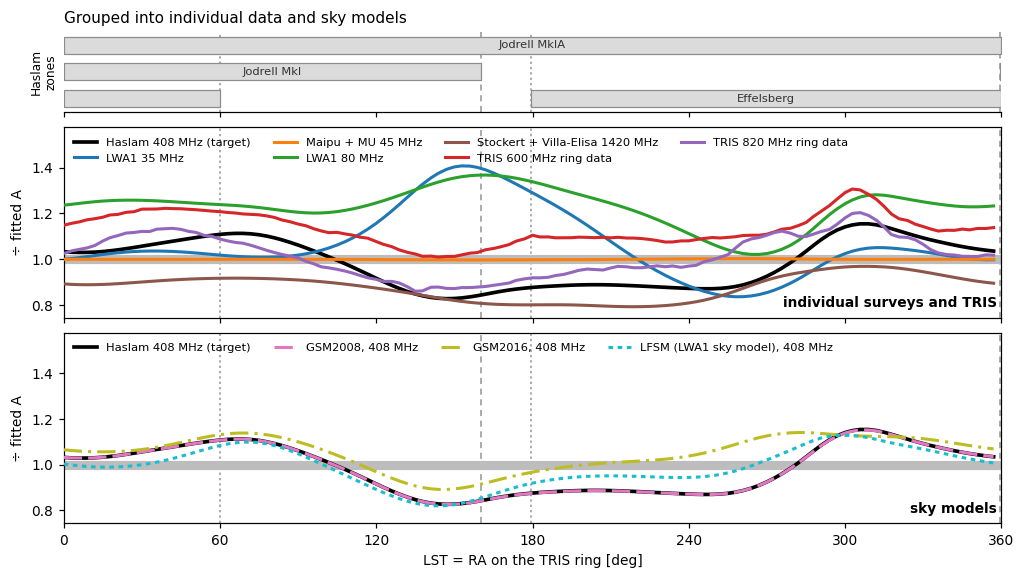

{'LWA1 35 MHz': '4.65°', 'Maipu + MU 45 MHz': '4.60°', 'LWA1 80 MHz': '2.04°', 'Stockert + Villa-Elisa 1420 MHz': '0.59°'}


In [15]:
def grouped_7d(groups, title, fname):
    # One ratio-to-A panel per group, under Figure 7d's Haslam zone strip.
    # groups: [(panel title, {label: series at 408 MHz})]; series colours come from C7D.
    fig, axs = plt.subplots(len(groups) + 1, 1, figsize=(11, 1.0 + 2.4 * len(groups)), sharex=True,
                            gridspec_kw=dict(height_ratios=[0.42] + [1] * len(groups), hspace=0.1))
    axz = axs[0]
    for row, (name, start, end, d_lo, d_hi, ls) in enumerate(ZONES):
        segs = ra_segments(start, end)
        axz.broken_barh([(a, b - a) for a, b in segs], (row - 0.32, 0.64), color="0.86", edgecolor="0.55", lw=0.8)
        a, b = max(segs, key=lambda sg: sg[1] - sg[0])
        axz.text((a + b) / 2, row, name, ha="center", va="center", fontsize=7.5, color="0.2")
        if start is not None:
            for a_ in axs:
                for edge in (start, end):
                    a_.axvline(edge, color="0.4", lw=1.0, ls=ls, alpha=0.7, zorder=0)
    axz.set_ylim(len(ZONES) - 0.5, -0.5); axz.set_yticks([])
    for side in ("left", "right", "top"):
        axz.spines[side].set_visible(False)
    axz.set_ylabel("Haslam\nzones", fontsize=8)
    axz.set_title(title, loc="left", fontsize=10)
    allr = []
    for a_, (gtitle, series) in zip(axs[1:], groups):
        a_.axhline(1, color="#bdbdbd", lw=6, zorder=1)
        a_.plot(inp.ra, HASLAM_408 / A_NT, "-", color="k", lw=2.4, label="Haslam 408 MHz (target)", zorder=3)
        for label, (key, v, ls) in series.items():
            r = v / A_NT
            a_.plot(inp.ra, r, color=C7D[key], ls=ls, lw=2, label=label, zorder=4)  # over Haslam: GSM2008 tracks it
            allr.append(r)
        a_.set_ylabel("÷ fitted A")
        a_.legend(fontsize=7.5, frameon=False, ncol=4, loc="upper left")
        a_.text(0.995, 0.04, gtitle, transform=a_.transAxes, ha="right", va="bottom", fontsize=9, weight="bold")
    lo_g, hi_g = np.nanpercentile(np.concatenate(allr + [HASLAM_408 / A_NT]), [0.5, 99.5])
    for a_ in axs[1:]:
        a_.set_ylim(min(0.75, lo_g - 0.05), max(1.35, hi_g + 0.2))
    axs[-1].set_xlabel("LST = RA on the TRIS ring [deg]")
    axs[-1].set_xlim(0, 360); axs[-1].set_xticks(np.arange(0, 361, 60))
    save(fig, fname)
    plt.show()

FIT_SOLID = {n: (n, v, "-") for n, v in SCALED.items()}
TRIS_S = {f"TRIS {f} MHz ring data": (name, TRIS_408[f], "-") for f, name in zip((600, 820), TRIS_NAMES)}
MODEL_S = {f"{n}, 408 MHz": (n, v, MODEL_STYLE[n][1]) for n, v in MODEL_408.items()}
ALL_DATA = {**FIT_SOLID, **TRIS_S}
freq_of = {**{n: FREQ[n] for n in SCALED}, **{lab: FREQ[k] for lab, (k, _, _) in TRIS_S.items()}}

grouped_7d([("below 408 MHz", {k: v for k, v in ALL_DATA.items() if freq_of[k] < NU_REF}),
            ("at 408 MHz: sky models", MODEL_S),
            ("above 408 MHz", {k: v for k, v in ALL_DATA.items() if freq_of[k] > NU_REF})],
           "Grouped by frequency relative to Haslam (408 MHz)", "fig07e_scaled_tods_by_frequency")

FWHM_OF = {n: m["fwhm_deg"] for m in inp.fit_maps for n in [m["name"]] if n in SCALED}
grouped_7d([(f"TRIS beam ({inp.target_fwhm:.1f}°)", TRIS_S),
            ("native FWHM 2–5°", {n: v for n, v in FIT_SOLID.items() if 1 < FWHM_OF[n] <= 5}),
            ("native FWHM ≤ 1° (Haslam 0.93°)", {n: v for n, v in FIT_SOLID.items() if FWHM_OF[n] <= 1})],
           "Grouped by native angular resolution (all observed through the TRIS beam)",
           "fig07f_scaled_tods_by_resolution")

grouped_7d([("individual surveys and TRIS", ALL_DATA), ("sky models", MODEL_S)],
           "Grouped into individual data and sky models", "fig07g_scaled_tods_data_vs_models")
print({n: f"{FWHM_OF[n]:.2f}°" for n in FWHM_OF})


---
## Figure 8 — Pixel-by-pixel residuals, every pixel

The residual $(T_\mathrm{data} - T_\mathrm{fit})/\sigma$ of every survey at every stripe
pixel (map route), against frequency. Boxes show the 25–75% range; whiskers the 5–95%.

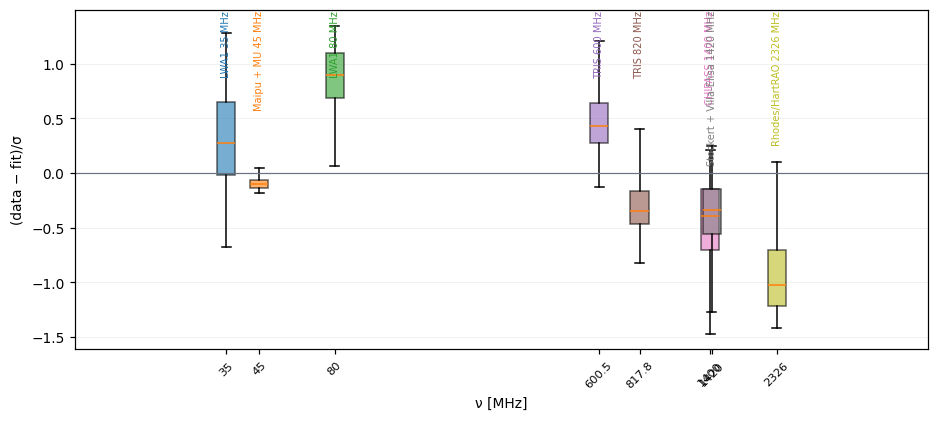

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
data, pos, cols = [], [], []
for name in names:
    v = MR["resid_norm"][name]
    v = v[np.isfinite(v)]
    data.append(v); pos.append(np.log10(FREQ[name])); cols.append(COLOUR[name])
bp = ax.boxplot(data, positions=pos, widths=0.06, whis=(5, 95), showfliers=False, patch_artist=True)
for patch, c in zip(bp["boxes"], cols):
    patch.set_facecolor(c); patch.set_alpha(0.6)
ax.axhline(0, color="#6b7280", lw=0.8)
ax.set_xticks(pos); ax.set_xticklabels([f"{FREQ[n]:g}" for n in names], rotation=45, fontsize=7.5)
ax.set_xlabel("ν [MHz]"); ax.set_ylabel("(data − fit)/σ")
ax.grid(alpha=0.18, lw=0.6, axis="y")
for name, x in zip(names, pos):
    ax.text(x, ax.get_ylim()[1], name.split(" (")[0], rotation=90, fontsize=6.5, va="top", ha="center", color=COLOUR[name])
save(fig, "fig08_residuals_by_survey")
plt.show()

---
## Figure 9 — χ² maps

χ²/dof of the per-pixel fit and the number of points behind it (map route), and χ²/dof
along the ring (TOD route). Five surveys carry an assumed 10% error, so χ² is indicative.

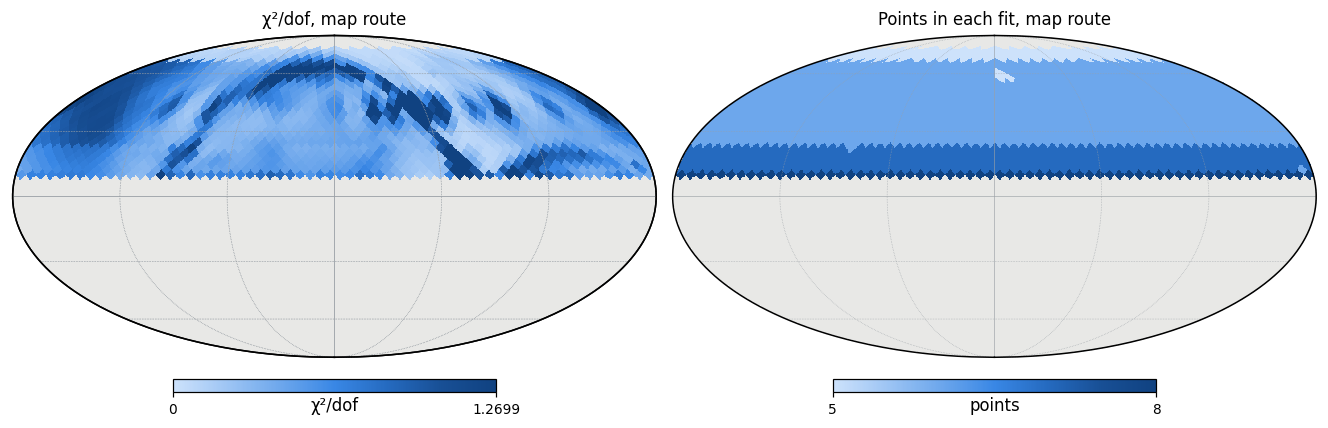

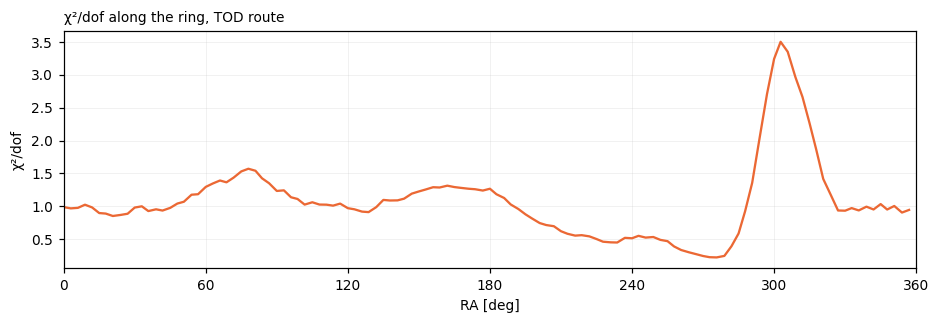

In [17]:
fig = plt.figure(figsize=(12, 3.8))
hp.mollview(MR["chi2_dof"], coord="C", sub=(1, 2, 1), fig=fig.number, cmap=SEQ, min=0,
            max=float(np.nanpercentile(MR["chi2_dof"], 95)), unit="χ²/dof", title="χ²/dof, map route", **MKW)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
hp.mollview(MR["n"], coord="C", sub=(1, 2, 2), fig=fig.number, cmap=SEQ, min=np.nanmin(MR["n"]),
            max=np.nanmax(MR["n"]), unit="points", title="Points in each fit, map route", **MKW)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
save(fig, "fig09a_chi2_maps")
plt.show()
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(inp.ra, TR["chi2_dof"], "-", color="#eb6834", lw=1.5)
ax.set_xlabel("RA [deg]"); ax.set_ylabel("χ²/dof"); ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 60))
ax.set_title("χ²/dof along the ring, TOD route", fontsize=9, loc="left"); ax.grid(alpha=0.18, lw=0.6)
save(fig, "fig09b_chi2_tod")
plt.show()

---
## Figure 10 — β maps

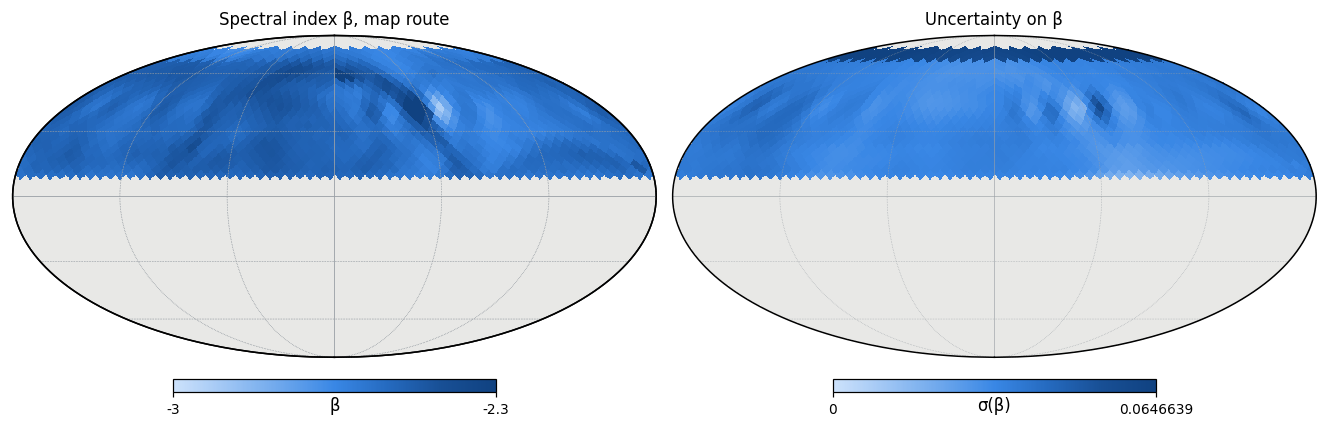

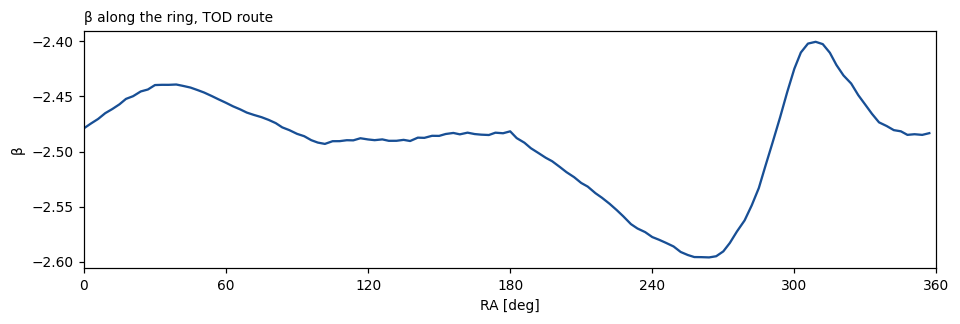

In [18]:
fig = plt.figure(figsize=(12, 3.8))
hp.mollview(MR["beta"], coord="C", sub=(1, 2, 1), fig=fig.number, cmap=SEQ, min=-3.0, max=-2.3,
            unit="β", title="Spectral index β, map route", **MKW)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
hp.mollview(MR["sigma_beta"], coord="C", sub=(1, 2, 2), fig=fig.number, cmap=SEQ, min=0,
            max=float(np.nanpercentile(MR["sigma_beta"], 98)), unit="σ(β)", title="Uncertainty on β", **MKW)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
save(fig, "fig10a_beta_maps")
plt.show()
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(inp.ra, TR["beta"], "-", color="#184f95", lw=1.5)
# ax.axhspan(-3.0, -2.5, color="0.92", lw=0, zorder=0)
ax.set_xlabel("RA [deg]"); ax.set_ylabel("β"); ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 60))
ax.set_title("β along the ring, TOD route", fontsize=9, loc="left"); # ax.grid(alpha=0.18, lw=0.6)
save(fig, "fig10b_beta_tod")
plt.show()

---
## Figure 11 — The corrected Haslam at full resolution

The target at full resolution (nside 512), drawn in equatorial. Each route's nside 16
correction is interpolated smoothly onto the full-resolution grid and added **inside the
TRIS stripe**; outside, the map is the original. This applies a 23°-scale correction to a
56′ map, the uniform-per-patch first pass of stage 4. A visible step at the stripe edge is
the correction's own value there.

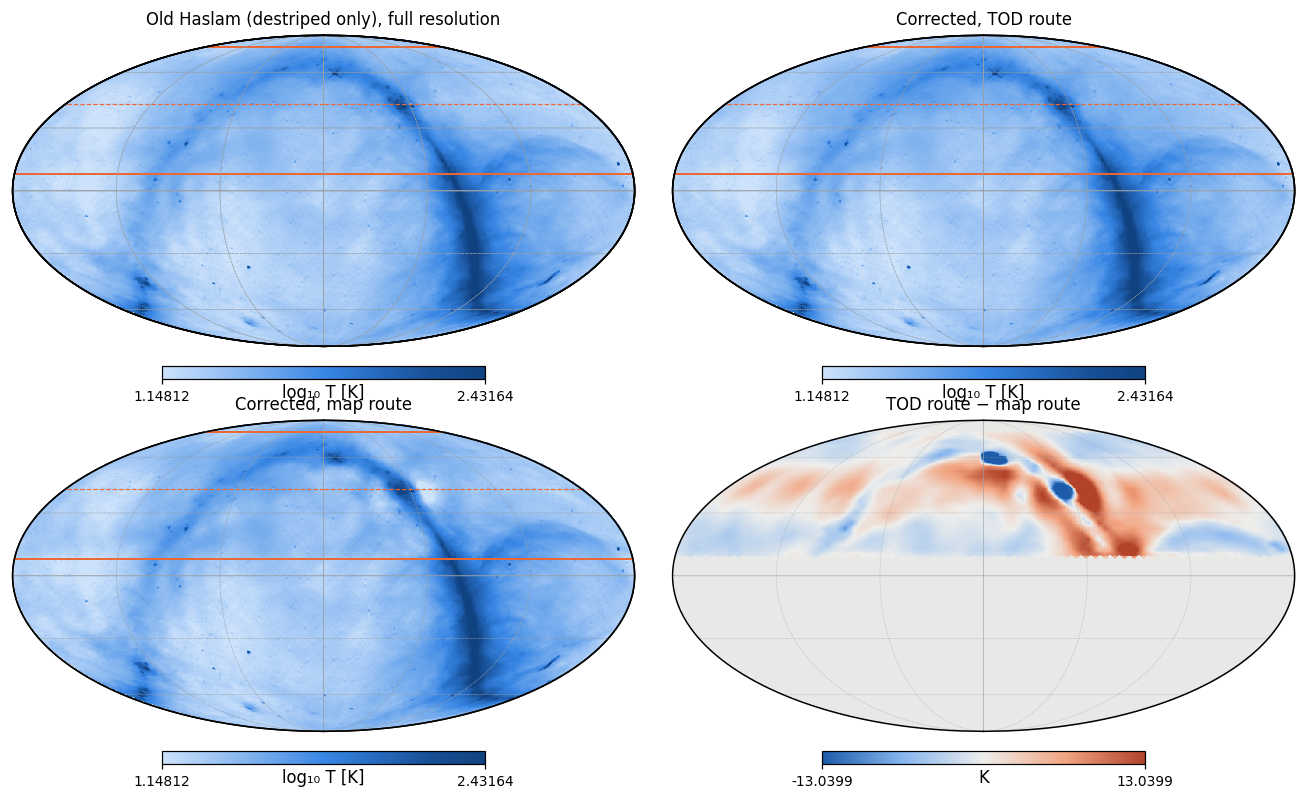

In [19]:
FULL = {"TOD route": sp.apply_full_resolution(inp, TR["delta"]),
        "map route": sp.apply_full_resolution(inp, np.where(inb, MR["delta"], 0.0))}
old_full = FULL["TOD route"]["old"]
lo, hi = np.log10(np.nanpercentile(old_full, 1)), np.log10(np.nanpercentile(old_full, 99.5))
fig = plt.figure(figsize=(12, 7.0))
for k, (title, m) in enumerate([("Old Haslam (destriped only), full resolution", old_full),
                                ("Corrected, TOD route", FULL["TOD route"]["corrected"]),
                                ("Corrected, map route", FULL["map route"]["corrected"])]):
    hp.mollview(np.log10(np.clip(m, 1e-3, None)), coord="C", sub=(2, 2, k + 1), fig=fig.number,
                cmap=SEQ, min=lo, max=hi, unit="log₁₀ T [K]", title=title, **MKW)
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
    stripe_lines("C")
diff = FULL["TOD route"]["corrected"] - FULL["map route"]["corrected"]
span = float(np.nanpercentile(np.abs(diff[FULL["TOD route"]["stripe"]]), 98))
hp.mollview(np.where(FULL["TOD route"]["stripe"], diff, np.nan), coord="C", sub=(2, 2, 4), fig=fig.number,
            cmap=DIV, min=-span, max=span, unit="K", title="TOD route − map route", **MKW)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
save(fig, "fig11_corrected_full_resolution")
plt.show()

---
## Figure 12 — T–T plots

Every pair of maps, pixel by pixel on the nside 16 grid, as CMB-subtracted RJ temperatures
(log–log). **Raw:** each map rotated into equatorial and averaged onto nside 16, with no
smoothing, so the surveys keep their own beams. **Beam-convolved:** each map matched to the
TRIS beam first, with the kernel set by `beam_matching.kernel` (in use: the 23.366° circular Gaussian; implemented, not in use: the measured,
elliptical TRIS beam; `moonrunes/elliptical_beam.py`). The TRIS maps are stage 1's in both, since they have no raw-beam version.
Each panel quotes the correlation of log T.

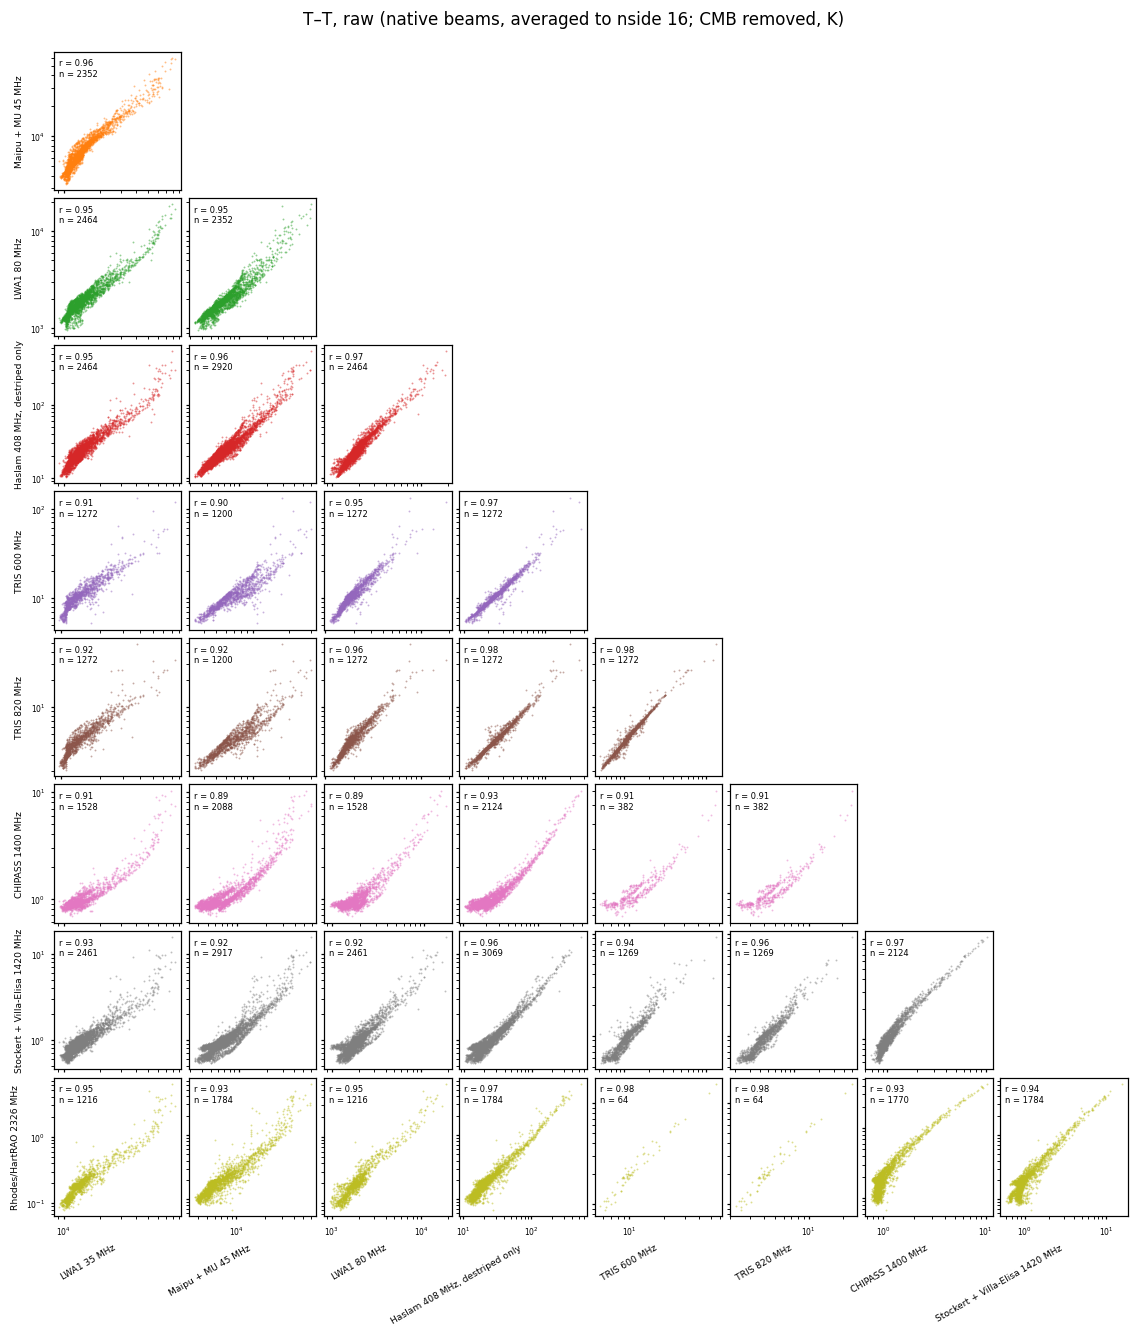

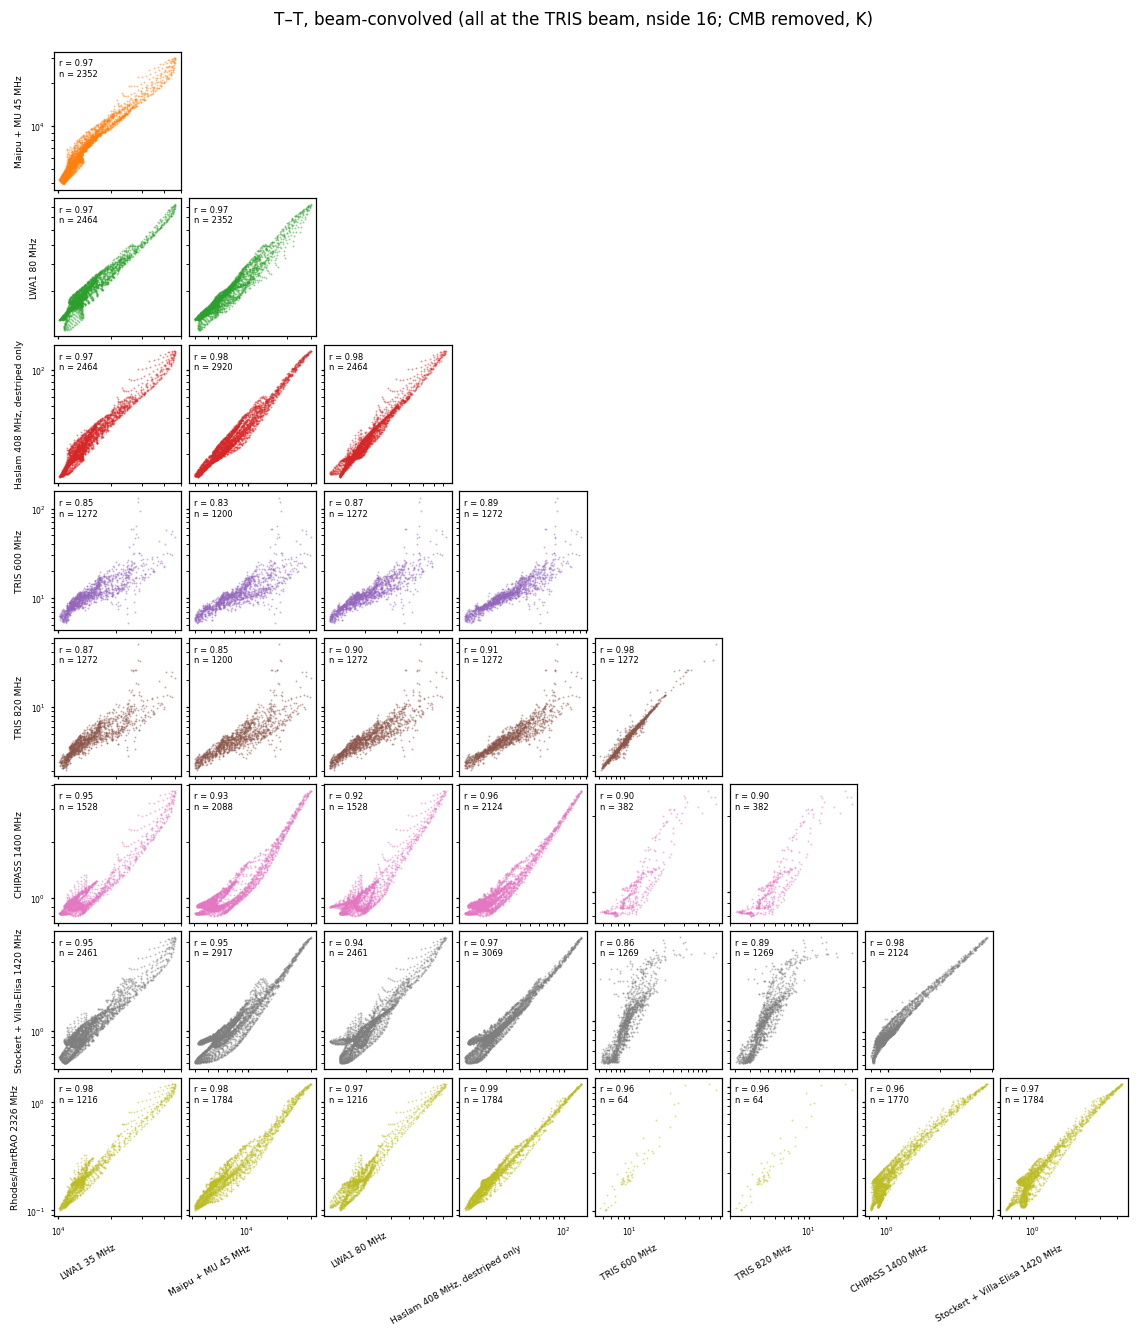

In [20]:
def tt_values(source):
    vals = {}
    for m in inp.fit_maps + [inp.target]:
        vals[m["name"]] = sky_maps.rj_excess(source[m["name"]], m)
    for f, name in zip((600, 820), TRIS_NAMES):
        nu = float(inp.stage1["effective_freq_mhz"][inp.stage1.index(f)])
        vals[name] = inp.tris_map[nu][0] - sky_maps.cmb_rj_k(nu)
    return vals

def corner(vals, title, fname):
    from matplotlib.ticker import NullFormatter, LogLocator
    names_ = [n for n in ORDER if n in vals]
    n = len(names_) - 1                       # rows: names_[1:], columns: names_[:-1]
    fig, axes = plt.subplots(n, n, figsize=(1.45 * n + 1, 1.45 * n + 1), squeeze=False)
    for i in range(n):
        for j in range(n):
            ax = axes[i, j]
            yi, xj = names_[i + 1], names_[j]
            if j > i:
                ax.axis("off"); continue
            x, y = vals[xj], vals[yi]
            ok = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
            if ok.sum() > 2:
                ax.scatter(x[ok], y[ok], s=1.5, color=COLOUR[yi], alpha=0.5, lw=0)
                ax.set_xscale("log"); ax.set_yscale("log")
                r = np.corrcoef(np.log10(x[ok]), np.log10(y[ok]))[0, 1]
                ax.text(0.04, 0.95, f"r = {r:.2f}\nn = {ok.sum()}", transform=ax.transAxes,
                        fontsize=5.5, va="top")
            for axis in (ax.xaxis, ax.yaxis):
                axis.set_major_locator(LogLocator(numticks=3))
                axis.set_minor_formatter(NullFormatter())
            ax.tick_params(which="both", labelsize=5, length=2,
                           labelleft=(j == 0), labelbottom=(i == n - 1))
            if j == 0:
                ax.set_ylabel(yi.split(" (")[0], fontsize=6)
            if i == n - 1:
                ax.set_xlabel(xj.split(" (")[0], fontsize=6, rotation=30, ha="right")
    fig.suptitle(title, fontsize=11)
    fig.subplots_adjust(wspace=0.06, hspace=0.06, top=0.95)
    save(fig, fname)
    plt.show()

corner(tt_values(inp.raw16), "T–T, raw (native beams, averaged to nside 16; CMB removed, K)", "fig12a_tt_raw")
corner(tt_values(inp.grid), "T–T, beam-convolved (all at the TRIS beam, nside 16; CMB removed, K)", "fig12b_tt_beam_convolved")

---
## Figure 13 — β from the T–T plots

For every pair of maps in Figure 12 (lower frequency $\nu_1$, higher $\nu_2$), a straight
line is fitted to the T–T scatter **in linear temperature**, over every pixel where both
maps have a positive value:

$$T_2 = a\,T_1 + b, \qquad \beta = \frac{\ln a}{\ln(\nu_2/\nu_1)}.$$

The slope carries the spectrum. Any constant offset between the two maps (a zero-level
error, a residual monopole) goes into the intercept $b$, so it does not bias β. That
makes this a check on the SED fits, which do assume both zero levels are right.

**Error bars:** 68% range of β over 1000 bootstrap resamplings of the pixels. Pixels are
correlated within a beam, much more so after smoothing to the TRIS beam, so these are
lower limits. Pairs closer than a factor 1.3 in frequency are left out (CHIPASS and
Stockert at 1.40/1.42 GHz; the two ARCADE 2 bands are excluded from these studies anyway): there, $\ln(\nu_2/\nu_1)$ is so small that any
calibration difference becomes a huge β. Pairs with fewer than 20 shared pixels are left
out too.

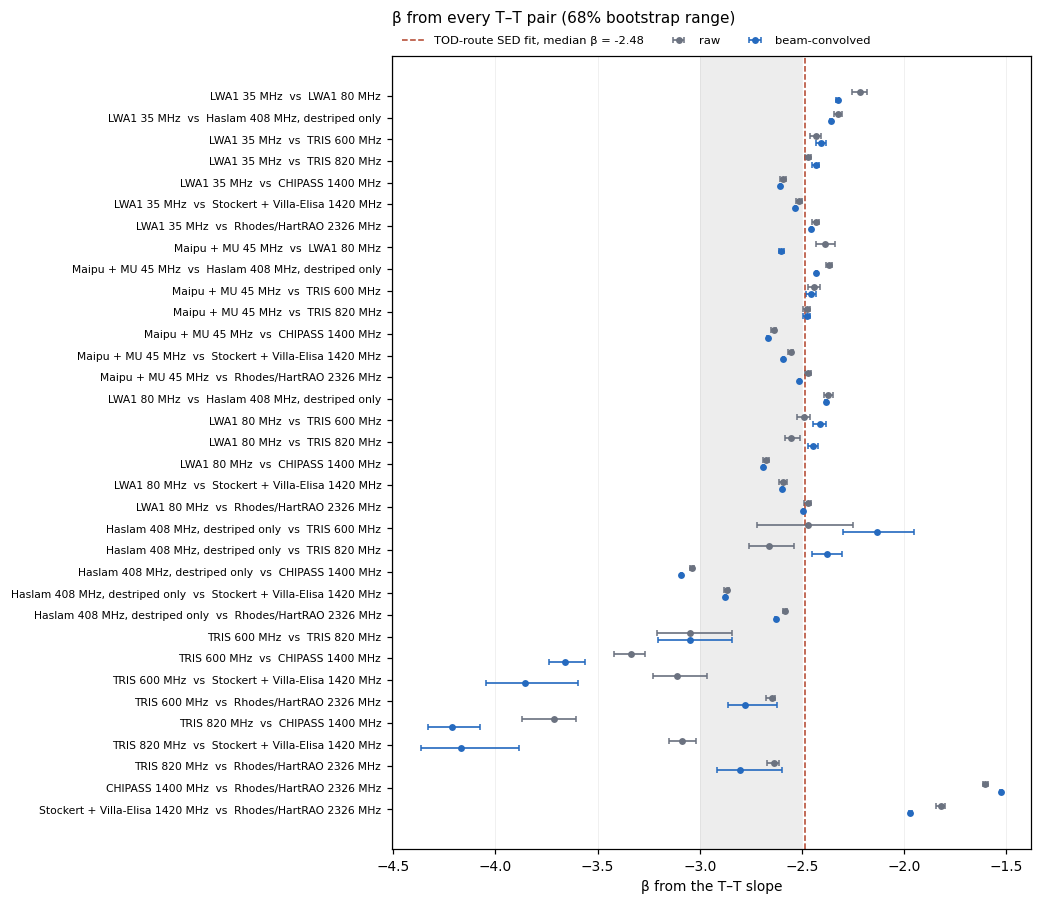

pair                                                                 raw β     n       beam-conv β     n
LWA1 35 MHz  vs  LWA1 80 MHz                                 -2.215 ±0.038  2464     -2.326 ±0.007  2464
LWA1 35 MHz  vs  Haslam 408 MHz, destriped only              -2.325 ±0.020  2464     -2.359 ±0.004  2464
LWA1 35 MHz  vs  TRIS 600 MHz                                -2.429 ±0.029  1272     -2.406 ±0.024  1272
LWA1 35 MHz  vs  TRIS 820 MHz                                -2.471 ±0.016  1272     -2.432 ±0.018  1272
LWA1 35 MHz  vs  CHIPASS 1400 MHz                            -2.590 ±0.016  1528     -2.605 ±0.004  1528
LWA1 35 MHz  vs  Stockert + Villa-Elisa 1420 MHz             -2.512 ±0.014  2461     -2.532 ±0.003  2461
LWA1 35 MHz  vs  Rhodes/HartRAO 2326 MHz                     -2.430 ±0.019  1216     -2.454 ±0.003  1216
Maipu + MU 45 MHz  vs  LWA1 80 MHz                           -2.386 ±0.048  2352     -2.601 ±0.014  2352
Maipu + MU 45 MHz  vs  Haslam 408 MHz, destriped only  

In [21]:
MIN_RATIO, MIN_PIX, N_BOOT = 1.3, 20, 1000
rng = np.random.default_rng(1)

def tt_betas(vals):
    # beta, its 68% bootstrap range, and pixel count for every pair of maps, low freq first.
    names_ = [n for n in ORDER if n in vals]
    rows = []
    for i, lo in enumerate(names_):
        for hi in names_[i + 1:]:
            ratio = FREQ[hi] / FREQ[lo]
            x, y = vals[lo], vals[hi]
            ok = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
            if ratio < MIN_RATIO or ok.sum() < MIN_PIX:
                continue
            x, y = x[ok], y[ok]
            a = np.polyfit(x, y, 1)[0]
            idx = rng.integers(0, x.size, size=(N_BOOT, x.size))
            xb, yb = x[idx], y[idx]
            xm, ym = xb.mean(1, keepdims=True), yb.mean(1, keepdims=True)
            ab = ((xb - xm) * (yb - ym)).sum(1) / ((xb - xm) ** 2).sum(1)
            with np.errstate(invalid="ignore"):
                b = np.log(a) / np.log(ratio)
                bb = np.log(ab[ab > 0]) / np.log(ratio)
            lo16, hi84 = np.percentile(bb, [16, 84]) if bb.size else (np.nan, np.nan)
            rows.append(dict(lo=lo, hi=hi, beta=b, err=(b - lo16, hi84 - b), n=int(ok.sum())))
    return rows

TT_BETA = {"raw": tt_betas(tt_values(inp.raw16)), "beam-convolved": tt_betas(tt_values(inp.grid))}

short = lambda n: n.split(" (")[0]
pairs = [(r["lo"], r["hi"]) for r in TT_BETA["beam-convolved"]]
pairs += [p for p in ((r["lo"], r["hi"]) for r in TT_BETA["raw"]) if p not in pairs]
pairs.sort(key=lambda p: (FREQ[p[0]], FREQ[p[1]]))
ypos = {p: k for k, p in enumerate(pairs)}

fig, ax = plt.subplots(figsize=(7.5, 0.24 * len(pairs) + 1.2))
for (label, rows), dy, colour in zip(TT_BETA.items(), (-0.17, 0.17), ("#6b7280", "#256abf")):
    y = np.array([ypos[(r["lo"], r["hi"])] + dy for r in rows])
    b = np.array([r["beta"] for r in rows])
    err = np.array([r["err"] for r in rows]).T
    ax.errorbar(b, y, xerr=err, fmt="o", ms=3.5, lw=1.1, capsize=2, color=colour, label=label)
ax.axvline(np.nanmedian(TR["beta"]), color="#b2432a", lw=1, ls="--",
           label=f"TOD-route SED fit, median β = {np.nanmedian(TR['beta']):.2f}")
ax.axvspan(-3.0, -2.5, color="0.93", lw=0, zorder=0)
ax.set_yticks(range(len(pairs)))
ax.set_yticklabels([f"{short(lo)}  vs  {short(hi)}" for lo, hi in pairs], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("β from the T–T slope")
ax.grid(axis="x", alpha=0.2, lw=0.6)
ax.legend(fontsize=7.5, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
ax.set_title("β from every T–T pair (68% bootstrap range)", loc="left", fontsize=10, pad=22)
save(fig, "fig13_tt_beta")
plt.show()

print(f"{'pair':<58}{'raw β':>16}{'n':>6}{'beam-conv β':>18}{'n':>6}")
for p in pairs:
    cells = []
    for label in TT_BETA:
        r = next((r for r in TT_BETA[label] if (r["lo"], r["hi"]) == p), None)
        cells.append(f"{r['beta']:+7.3f} ±{max(r['err']):.3f}{r['n']:>6}" if r else f"{'—':>16}{'':>6}")
    print(f"{short(p[0]) + '  vs  ' + short(p[1]):<58}{cells[0]:>22}{cells[1]:>24}")


---
## Figure 13b — β matrix: T–T plots against the SED fit (map route)

Spectral indices for every pair of maps, measured two ways on **the same pixels** (the TRIS
stripe pixels where both maps have a value) and **the same beam-convolved maps** (every
survey matched to the TRIS beam on the nside 16 grid; TRIS = the stage 1 maps):

* **T–T (lower triangle):** the slope $a$ of a straight-line fit $T_2 = aT_1 + b$ to the
  pair's beam-convolved, CMB-free temperatures, so $\beta = \ln a/\ln(\nu_2/\nu_1)$. This is
  Figure 13's method, restricted to the stripe. It uses only those two maps and is blind to
  their zero levels.
* **SED fit (upper triangle):** the median, over the same pixels, of the β the map-route
  power-law fit returns at each pixel. That β uses *every* survey at the pixel, not just
  the pair.

Each cell is coloured by β and labelled with its value; the T–T cells also give the
bootstrap error (68% range over 1000 resamplings of the pixels, a lower limit because
pixels within a beam are correlated). **Right:** T–T minus SED for each pair.

Blank cells: pairs closer than ×1.3 in frequency (their β is ill-determined, Figure 13),
or with fewer than 20 shared stripe pixels.

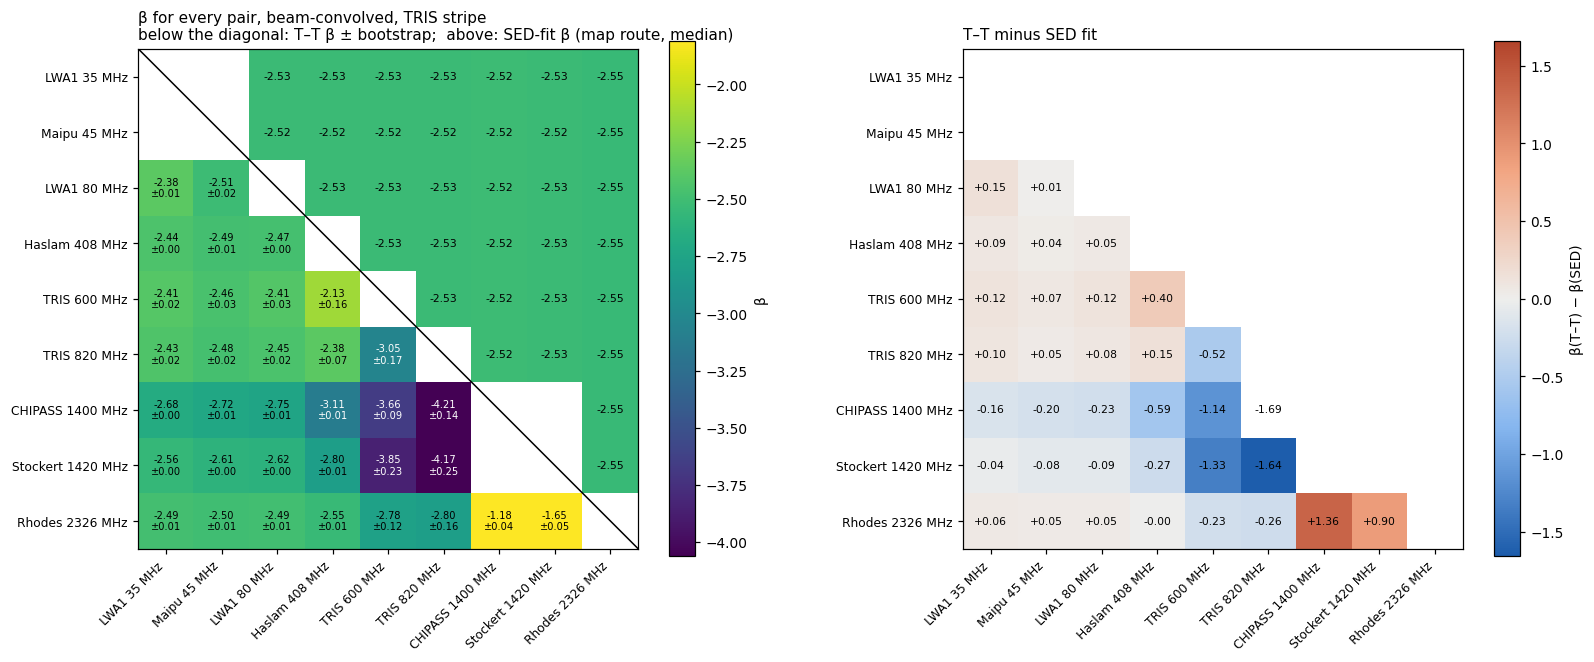

34 pairs compared; β(T–T) − β(SED): median +0.023, rms 0.591, range -1.691 to +1.364

pair                                       pixels           β T–T    β SED  T–T − SED
LWA1 35 MHz vs LWA1 80 MHz                   1272   -2.380 ±0.008   -2.528     +0.148
Maipu 45 MHz vs LWA1 80 MHz                  1200   -2.515 ±0.016   -2.524     +0.009
LWA1 35 MHz vs Haslam 408 MHz                1272   -2.438 ±0.003   -2.528     +0.090
Maipu 45 MHz vs Haslam 408 MHz               1200   -2.487 ±0.005   -2.524     +0.037
LWA1 80 MHz vs Haslam 408 MHz                1272   -2.473 ±0.003   -2.528     +0.055
LWA1 35 MHz vs TRIS 600 MHz                  1272   -2.406 ±0.023   -2.528     +0.122
Maipu 45 MHz vs TRIS 600 MHz                 1200   -2.456 ±0.026   -2.524     +0.068
LWA1 80 MHz vs TRIS 600 MHz                  1272   -2.409 ±0.033   -2.528     +0.119
Haslam 408 MHz vs TRIS 600 MHz               1272   -2.132 ±0.164   -2.528     +0.396
LWA1 35 MHz vs TRIS 820 MHz                  1272   -2

In [22]:
MIN_RATIO_M, MIN_PIX_M, NBOOT_M = 1.3, 20, 1000
rng_m = np.random.default_rng(7)

# Beam-convolved, CMB-free values on the TRIS grid (the map route's inputs).
VALS_M = {}
for m in inp.fit_maps + [inp.target]:
    VALS_M[m["name"]] = np.asarray(sky_maps.rj_excess(inp.grid[m["name"]], m), dtype=float)
for f, name in zip((600, 820), TRIS_NAMES):
    nu = float(inp.stage1["effective_freq_mhz"][inp.stage1.index(f)])
    VALS_M[name] = inp.tris_map[nu][0] - sky_maps.cmb_rj_k(nu)
NAMES_M = [n for n in ORDER if n in VALS_M]
N_M = len(NAMES_M)

TT_M = np.full((N_M, N_M), np.nan)       # [hi, lo]: T-T beta
TT_E = np.full((N_M, N_M), np.nan)       # its bootstrap 68% half-width
SED_M = np.full((N_M, N_M), np.nan)      # [lo, hi]: median SED beta over the same pixels
NPIX_M = np.zeros((N_M, N_M), dtype=int)
for i, lo in enumerate(NAMES_M):
    for j in range(i + 1, N_M):
        hi = NAMES_M[j]
        ratio = FREQ[hi] / FREQ[lo]
        ok = BAND & np.isfinite(VALS_M[lo]) & np.isfinite(VALS_M[hi]) & np.isfinite(MR["beta"])
        if ratio < MIN_RATIO_M or ok.sum() < MIN_PIX_M:
            continue
        x, y = VALS_M[lo][ok], VALS_M[hi][ok]
        a = np.polyfit(x, y, 1)[0]
        idx = rng_m.integers(0, x.size, size=(NBOOT_M, x.size))
        xb, yb = x[idx], y[idx]
        xm, ym = xb.mean(1, keepdims=True), yb.mean(1, keepdims=True)
        ab = ((xb - xm) * (yb - ym)).sum(1) / ((xb - xm) ** 2).sum(1)
        bb = np.log(ab[ab > 0]) / np.log(ratio)
        if a > 0:
            TT_M[j, i] = np.log(a) / np.log(ratio)
            TT_E[j, i] = 0.5 * np.diff(np.percentile(bb, [16, 84]))[0] if bb.size else np.nan
        SED_M[i, j] = np.nanmedian(MR["beta"][ok])
        NPIX_M[i, j] = NPIX_M[j, i] = int(ok.sum())

short = lambda n: (n.split(" (")[0].replace("Stockert + Villa-Elisa", "Stockert").replace("Maipu + MU", "Maipu")
                   .replace("Rhodes/HartRAO", "Rhodes").replace("Haslam 408 MHz, destriped only", "Haslam 408 MHz"))
from matplotlib.colors import TwoSlopeNorm
fig, (ax, axd) = plt.subplots(1, 2, figsize=(17, 7.6), gridspec_kw=dict(width_ratios=[1, 1], wspace=0.32))
both = np.concatenate([TT_M[np.isfinite(TT_M)], SED_M[np.isfinite(SED_M)]])
lo_b, hi_b = np.percentile(both, [2, 98])
cmap_b = plt.get_cmap("viridis").copy(); cmap_b.set_bad("white")
mat = np.where(np.isfinite(TT_M), TT_M, SED_M)
im = ax.imshow(mat, cmap=cmap_b, vmin=lo_b, vmax=hi_b)
for i in range(N_M):
    for j in range(N_M):
        if i > j and np.isfinite(TT_M[i, j]):
            ax.text(j, i, f"{TT_M[i, j]:.2f}\n±{TT_E[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if TT_M[i, j] < (lo_b + hi_b) / 2 else "black")
        elif i < j and np.isfinite(SED_M[i, j]):
            ax.text(j, i, f"{SED_M[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if SED_M[i, j] < (lo_b + hi_b) / 2 else "black")
ax.plot([-0.5, N_M - 0.5], [-0.5, N_M - 0.5], color="k", lw=1)
ax.set_xticks(range(N_M)); ax.set_yticks(range(N_M))
ax.set_xticklabels([short(n) for n in NAMES_M], rotation=45, ha="right", fontsize=8)
ax.set_yticklabels([short(n) for n in NAMES_M], fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8, label="β")
ax.set_title("β for every pair, beam-convolved, TRIS stripe\nbelow the diagonal: T–T β ± bootstrap;  "
             "above: SED-fit β (map route, median)", loc="left", fontsize=10)

diff = np.full((N_M, N_M), np.nan)
for i in range(N_M):
    for j in range(i):
        if np.isfinite(TT_M[i, j]) and np.isfinite(SED_M[j, i]):
            diff[i, j] = TT_M[i, j] - SED_M[j, i]
span = float(np.nanpercentile(np.abs(diff), 98)) if np.isfinite(diff).any() else 1
cmap_d = DIV.copy(); cmap_d.set_bad("white")
imd = axd.imshow(diff, cmap=cmap_d, norm=TwoSlopeNorm(0, -span, span))
for i in range(N_M):
    for j in range(i):
        if np.isfinite(diff[i, j]):
            axd.text(j, i, f"{diff[i, j]:+.2f}", ha="center", va="center", fontsize=7)
axd.set_xticks(range(N_M)); axd.set_yticks(range(N_M))
axd.set_xticklabels([short(n) for n in NAMES_M], rotation=45, ha="right", fontsize=8)
axd.set_yticklabels([short(n) for n in NAMES_M], fontsize=8)
fig.colorbar(imd, ax=axd, shrink=0.8, label="β(T–T) − β(SED)")
axd.set_title("T–T minus SED fit", loc="left", fontsize=10)
save(fig, "fig13b_beta_matrix_tt_vs_sed")
plt.show()

d = diff[np.isfinite(diff)]
print(f"{np.isfinite(TT_M).sum()} pairs compared; β(T–T) − β(SED): median {np.median(d):+.3f}, "
      f"rms {np.std(d):.3f}, range {d.min():+.3f} to {d.max():+.3f}")
print(f"\n{'pair':<42}{'pixels':>7}{'β T–T':>16}{'β SED':>9}{'T–T − SED':>11}")
for i in range(N_M):
    for j in range(i):
        if np.isfinite(diff[i, j]):
            print(f"{short(NAMES_M[j]) + ' vs ' + short(NAMES_M[i]):<42}{NPIX_M[i, j]:7d}"
                  f"{TT_M[i, j]:+9.3f} ±{TT_E[i, j]:.3f}{SED_M[j, i]:+9.3f}{diff[i, j]:+11.3f}")

**Reading Figure 13b (run 2026-10-15, ARCADE 2 excluded).** 34 pairs are compared.
β(T–T) − β(SED) has a median of +0.09 and an rms of 0.59, from −1.62 to +1.44.

* **The SED-fit β barely changes from pair to pair** (−2.59 to −2.62). It is one β per
  pixel, fitted to *all* the surveys there, so it reflects the pixels a pair shares, not
  the pair itself. The T–T β is a two-map measurement, and the differences between the two
  show where individual surveys disagree with the overall power law.
* **Pairs among the low-frequency surveys and Stockert agree with the SED fit** to within
  ~0.03: LWA1 35 vs Stockert +0.03, Maipu 45 vs Stockert −0.02, LWA1 80 vs Stockert −0.03.
* **Pairs with a low-frequency survey and a 408–820 MHz map are flatter than the fit** by
  0.1–0.2 (e.g. LWA1 35 vs TRIS 600 +0.18). This is the spectral curvature again: one β
  for 35 MHz–2.3 GHz is steeper than the low-frequency end.
* **Pairs involving TRIS are the outliers.**
  * TRIS against a higher-frequency map is much steeper than the fit: TRIS 820 vs
    Stockert −1.58, TRIS 820 vs CHIPASS −1.62, TRIS 600 vs Stockert −1.26.
  * Haslam vs TRIS 600 is much flatter (+0.46).
  * Both mean TRIS is high relative to the surveys on either side of it: the same offset
    Figure 7d shows (TRIS 600 ~23% above the non-TRIS fit).
  * The TRIS stripe covers a narrow brightness range, so these slopes rest on little
    leverage, and their bootstrap errors (±0.1–0.25) are lower limits.
* **Rhodes/HartRAO against CHIPASS and Stockert** (+1.44, +0.98) repeats Figure 13's
  finding that the Rhodes temperature scale is inconsistent with its 1.4 GHz neighbours.
  It has only 64 stripe pixels.
* **Haslam vs the 1.4 GHz surveys is steeper than the fit** (vs Stockert −0.21, vs
  CHIPASS −0.52). Haslam is high relative to those maps, or they are low relative to it.
  The T–T slope cannot say which; only the absolute anchors can.

---
### Summary numbers

In [23]:
print(f"target: {inp.target['name']}")
print(f"map route: {int(inb.sum())} pixels; median β {np.nanmedian(MR['beta'][inb]):+.3f}; "
      f"median χ²/dof {np.nanmedian(MR['chi2_dof'][inb]):.2f}; best fit − old: median "
      f"{np.nanmedian(MR['delta'][inb]):+.2f} K ({100 * np.nanmedian(MR['delta'][inb] / MR['old'][inb]):+.1f}%)")
print(f"TOD route: 120 samples; median β {np.nanmedian(TR['beta']):+.3f}; median χ²/dof "
      f"{np.nanmedian(TR['chi2_dof']):.2f}; best fit − old along the ring: median "
      f"{np.nanmedian(TR['delta_tod']):+.2f} K ({100 * np.nanmedian(TR['delta_tod'] / TR['target_tod']):+.1f}%)")
print(f"figures written to {OUT}")

target: Haslam 408 MHz, destriped only
map route: 1272 pixels; median β -2.528; median χ²/dof 0.47; best fit − old: median +1.60 K (+6.1%)
TOD route: 120 samples; median β -2.485; median χ²/dof 0.99; best fit − old along the ring: median +3.22 K (+10.9%)
figures written to /Users/user/Documents/Codes/project3/moonrunes/outputs/paper_plots
